# Estatísticas finais: topologia, distribuição e desempenho em MDS

Este notebook lê os seis CSVs de análise em RESULTS_DIR, agrega por instância e gera
tabelas e figuras. delta_t_full.csv é opcional e serve somente para um gráfico descritivo.
As **variáveis explicativas** são as características dos grafos e a distribuição escolhida.
As **respostas** são o vencedor da melhor solução, o vencedor em cada gap, o melhor tempo
em cada gap e o gap da melhor solução em relação ao ótimo dms.

**Unidade de análise: uma instância.** Total e cauda são duas análises da mesma coleção,
não duas réplicas independentes. Os cinco gaps também são medidas da mesma instância.
As associações são exploratórias: não demonstram que uma propriedade topológica causa
uma diferença de desempenho.

| Pergunta | Análise | Figura |
|---|---|---|
| Quem vence e quantos empates existem? | Frequências e crédito fracionado nos empates conhecidos | Barras por objetivo |
| Quais métricas são redundantes? | Spearman entre características | Mapa de calor |
| Quais características acompanham tempos e gaps? | Spearman, permutação, IC bootstrap e Holm | Mapa de calor e dispersões |
| A relação persiste após considerar o tamanho? | Spearman parcial controlando n e m, descritivo | Tabela |
| Distribuição e algoritmo vencedor estão associados? | V de Cramér e teste por permutação | Contingência e proporções por distribuição |
| Os perfis topológicos diferem entre vencedores? | Kruskal–Wallis por permutação e tamanho de efeito | Boxplots com observações |
| Tempos e gaps diferem entre distribuições? | Kruskal–Wallis por permutação; pares com Cliff e Holm | Boxplots com observações |
| Total e cauda escolhem o mesmo modelo? | Concordância pareada e kappa | Matriz de transições |
| É possível prever o vencedor? | Árvore classificadora versus baseline, fora da amostra | Confusão e árvore ilustrativa |
| É possível prever tempo/gap? | Árvore regressora versus baseline, fora da amostra | Observado versus previsto |
| A distribuição acrescenta informação preditiva? | Mesmas divisões de validação: métricas, distribuição e ambas | Comparação dos escores |
| Qual a direção da diferença média de tempo? | Descrição de delta_t_full | Barras com sinal |

O notebook não executa os algoritmos de MDS nem ajusta novamente as distribuições.
Requer Python ≥ 3.10, numpy, pandas, scipy ≥ 1.10, matplotlib, seaborn,
scikit-learn ≥ 1.2 e IPython. Se necessário, instale no ambiente do kernel:

~~~python
%pip install "numpy>=1.24" "pandas>=2.1" "scipy>=1.10" "matplotlib>=3.7" "seaborn>=0.13" "scikit-learn>=1.2" ipython
~~~


## 1. Configuração

Execute as células na ordem. A configuração procura complex_networks.config.RESULTS_DIR,
inclusive quando o notebook está em notebooks/. Use RESULTS_DIR_OVERRIDE somente
se quiser indicar outro diretório.

As colunas instance, instancia e network são padronizadas internamente para instancia.
As tabelas são unidas pelo nome da instância, sem extensão .txt.gz. A coluna origem
da tabela de distribuições é apenas informativa; total e cauda são separados por escopo.

Em otimos.csv, **dms contém os valores comprovadamente ótimos** e é a única coluna
de valores utilizada. A coluna optimum, se existir, é ignorada.

As análises utilizam os CSVs e não precisam abrir os grafos de
RESULTS_DIR / "raw" ou RESULTS_DIR / "extend".

A validação das árvores separa as instâncias automaticamente. Não é necessário
informar famílias ou qualquer mapeamento adicional. A complexidade das árvores
é fixada antes de avaliar.


In [1]:
from pathlib import Path
import os
import sys
import re
import ast
import json
import html
import hashlib
import importlib
import importlib.util
import platform
import warnings
from datetime import datetime, timezone
from itertools import combinations

import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import StratifiedKFold, KFold
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    mean_absolute_error, r2_score, confusion_matrix,
    ConfusionMatrixDisplay, cohen_kappa_score,
)
from IPython.display import display, Markdown

RESULTS_DIR_OVERRIDE = None  # Exemplo: Path("/home/fernando/complex-networks/results")
CSV_SEP = ","

SEED = 42
ALPHA = 0.05
N_PERM = 19999               # Resolução mínima do p Monte Carlo = 1/(N_PERM + 1).
N_BOOT = 1000
MIN_N_ASSOC = 8
MIN_N_GROUP = 3
MIN_N_MODEL = 15
CV_FOLDS = 5
TREE_MAX_DEPTH = 3
TREE_MIN_SAMPLES_LEAF = 3
IMPORTANCE_REPEATS = 5
RUN_POSTHOC = True
INCLUDE_TIES_IN_MODELS = False
ALLOW_MIXED_BUDGETS_MODELS = False
SAVE_FIGURES = True
FIGURE_FORMATS = ("png", "pdf")
DPI = 220
MAX_HEATMAP_ROWS = 60
ILLUSTRATION_CLASS_TARGET = "vencedor_gap1"
ILLUSTRATION_REG_TARGET = "tempo_gap1_s"

GAPS = [50, 25, 10, 5, 1]
ALGORITHMS = ["DemDS", "IG", "Greedy"]
SCOPES = ["total", "cauda"]
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:.6g}")


In [2]:
def find_results_dir():
    override = os.environ.get("FINAL_STATS_RESULTS_DIR")
    if override:
        return Path(override).expanduser().resolve()
    if RESULTS_DIR_OVERRIDE is not None:
        return Path(RESULTS_DIR_OVERRIDE).expanduser().resolve()

    here = Path.cwd().resolve()
    for parent in [here, *here.parents]:
        src = parent / "src"
        if (src / "complex_networks").is_dir() and str(src) not in sys.path:
            sys.path.insert(0, str(src))
            break
    if importlib.util.find_spec("complex_networks") is not None:
        config = importlib.import_module("complex_networks.config")
        return Path(config.RESULTS_DIR).expanduser().resolve()

    for candidate in [here, here / "results", here.parent / "results"]:
        if (candidate / "general_metrics.csv").is_file():
            return candidate
    raise FileNotFoundError(
        "Não encontrei RESULTS_DIR. Defina RESULTS_DIR_OVERRIDE na célula de configuração."
    )


RESULTS_DIR = find_results_dir()
if not RESULTS_DIR.is_dir():
    raise FileNotFoundError(f"Diretório inexistente: {RESULTS_DIR}")
RUN_ID = datetime.now(timezone.utc).strftime("run_%Y%m%d_%H%M%S_%f_UTC")
OUTPUT_DIR = RESULTS_DIR / "final_stats" / RUN_ID
TABLE_DIR, FIG_DIR = OUTPUT_DIR / "tabelas", OUTPUT_DIR / "figuras"
TABLE_DIR.mkdir(parents=True, exist_ok=False)
FIG_DIR.mkdir(parents=True, exist_ok=False)
TABLES, AUDIT, MODEL_NOTES = {}, [], []


def note(topic, message, n=None):
    AUDIT.append({"tema": topic, "mensagem": str(message), "n": n})


def rng_for(*parts):
    digest = hashlib.sha256("|".join(map(str, (SEED, *parts))).encode()).digest()
    return np.random.default_rng(int.from_bytes(digest[:8], "little"))


def save_table(frame, name, show=True, limit=20):
    frame = pd.DataFrame(frame).copy()
    TABLES[name] = frame
    frame.to_csv(TABLE_DIR / f"{name}.csv", index=False, encoding="utf-8-sig")
    if show:
        display(frame.head(limit))
        if len(frame) > limit:
            print(f"{len(frame)} linhas; tabela completa em {name}.csv.")
    return frame


def finish_figure(fig, name):
    fig.tight_layout()
    if SAVE_FIGURES:
        for extension in FIGURE_FORMATS:
            fig.savefig(FIG_DIR / f"{name}.{extension}", dpi=DPI, bbox_inches="tight")
    plt.show()
    plt.close(fig)


print(f"Entrada: {RESULTS_DIR}")
print(f"Saída desta execução: {OUTPUT_DIR}")
print(f"Permutações: {N_PERM}; bootstrap: {N_BOOT}; alpha: {ALPHA}.")


Entrada: /home/fernando/complex-networks/results
Saída desta execução: /home/fernando/complex-networks/results/final_stats/run_20261120_032308_235404_UTC
Permutações: 19999; bootstrap: 1000; alpha: 0.05.


## 2. Leitura, normalização e auditoria

Os arquivos originais são apenas lidos. Colunas vazias criadas por uma vírgula final
são removidas; uma coluna sem nome que contenha dados gera erro, pois pode indicar
um dicionário de parâmetros não protegido por aspas no CSV.

As tabelas são agregadas pelo nome da instância, removendo somente espaços nas extremidades.
Uma duplicação dentro da mesma chave gera erro; total e cauda permanecem separados.
Valores -1 de distância/diâmetro são tratados como ausentes. Modularidade negativa
permanece válida.

Em cada gap, um tempo vazio significa **registro ausente**. Marcadores explícitos
como infinito, -1, timeout ou "não atingido" indicam alvo não atingido. Zero é um
tempo observado e é preservado. Nenhum desses casos é substituído pelo limite de tempo.


In [3]:
def normalize_text(value):
    import unicodedata
    text = "" if pd.isna(value) else str(value).strip().casefold()
    return "".join(c for c in unicodedata.normalize("NFKD", text)
                   if not unicodedata.combining(c))


def clean_header(value):
    value = html.unescape(str(value)).replace("*", "").strip().lower()
    return re.sub(r"[^\w-]+", "_", value).strip("_")


def instance_name(value):
    if pd.isna(value) or not str(value).strip():
        raise ValueError("Há uma chave de instância vazia.")
    value = str(value).strip()
    return value


def read_input(filename, required):
    path = RESULTS_DIR / filename
    if not path.is_file():
        raise FileNotFoundError(f"Arquivo obrigatório ausente: {path}")
    df = pd.read_csv(path, sep=CSV_SEP, dtype=str, encoding="utf-8-sig")
    for col in list(df.columns):
        if str(col).lower().startswith("unnamed:") or not str(col).strip():
            if df[col].notna().any():
                raise ValueError(f"{filename}: coluna sem nome contém dados; confira as aspas do CSV.")
            df = df.drop(columns=col)
    df.columns = [clean_header(c) for c in df.columns]
    if df.columns.duplicated().any():
        raise ValueError(f"{filename}: nomes de colunas repetidos após limpeza.")
    df = df.rename(columns={"network": "instancia", "instance": "instancia"})
    missing = set(required) - set(df.columns)
    if missing:
        raise ValueError(f"{filename}: faltam colunas {sorted(missing)}. Lidas: {list(df.columns)}")
    if "instancia" in df:
        df["instancia"] = df["instancia"].map(instance_name)
    note(filename, "Arquivo lido.", len(df))
    return df


def unique_key(df, columns, label):
    duplicated = df.duplicated(columns, keep=False)
    if duplicated.any():
        example = df.loc[duplicated, columns].head(12).to_dict("records")
        raise ValueError(f"{label}: chave {columns} duplicada. Exemplos: {example}")


def numbers(series, label, missing_negative=False):
    original = series.astype("string").str.strip()
    # Aceita vírgula decimal somente se o campo já foi lido corretamente pelo CSV.
    clean = original.str.replace(",", ".", regex=False)
    result = pd.to_numeric(clean, errors="coerce").astype(float)
    result = result.replace([np.inf, -np.inf], np.nan)
    known_missing = original.isna() | original.map(normalize_text).isin(
        {"", "-", "–", "—", "nan", "none", "null", "na", "n/a"}
    )
    invalid = result.isna() & ~known_missing
    if invalid.any():
        note(label, f"Valores não numéricos/infinitos: {original[invalid].unique()[:8].tolist()}",
             int(invalid.sum()))
    if missing_negative:
        bad = result < 0
        if bad.any():
            note(label, "Sentinelas negativas convertidas em ausentes.", int(bad.sum()))
            result = result.mask(bad)
    return result


metrics = read_input("general_metrics.csv", ["instancia", "n_nodes", "n_edges", "average_degree"])
gap_winners = read_input("mds_gaps_final.csv", ["instancia", *[f"gap{g}" for g in GAPS]])
solutions = read_input("mds_solucoes_final.csv",
                       ["instancia", "melhor_algoritmo", "melhor_sol", "limite_s"])
times = read_input("melhores_tempos_full.csv", ["instancia", *[f"gap{g}" for g in GAPS]])
distributions = read_input("distribuicoes_escolhidas.csv",
                           ["instancia", "escopo", "distribuicao_escolhida"])
references = read_input("otimos.csv", ["instancia", "dms"])[["instancia", "dms"]]

for label, frame in [("métricas", metrics), ("vencedores", gap_winners),
                     ("soluções", solutions), ("tempos", times), ("referências", references)]:
    unique_key(frame, ["instancia"], label)

if metrics.empty:
    raise ValueError("general_metrics.csv não contém instâncias para analisar.")

SCOPE_ALIASES = {"total": "total", "full": "total", "completo": "total",
                 "cauda": "cauda", "tail": "cauda"}
distributions["escopo"] = distributions["escopo"].map(normalize_text).map(SCOPE_ALIASES)
if distributions["escopo"].isna().any():
    raise ValueError("Há escopos não reconhecidos. Use total/cauda ou amplie SCOPE_ALIASES.")
unique_key(distributions, ["instancia", "escopo"], "distribuições")

METRIC_COLUMNS = [
    "n_nodes", "n_edges", "average_degree", "mean_clustering_degree_gt_1",
    "clustering_eligible_nodes", "transitivity", "average_shortest_path_length",
    "diameter", "density", "n_components", "modularity",
]
for col in METRIC_COLUMNS:
    if col not in metrics:
        note(col, "Métrica ausente; as análises disponíveis continuam.")
        metrics[col] = np.nan
    metrics[col] = numbers(metrics[col], col,
                          missing_negative=col in {"average_shortest_path_length", "diameter"})

if metrics["n_nodes"].isna().any() or (metrics["n_nodes"] <= 0).any():
    raise ValueError("n_nodes deve ser conhecido e positivo em todas as instâncias.")
for col in ["n_edges", "average_degree", "clustering_eligible_nodes", "n_components"]:
    if (metrics[col].dropna() < 0).any():
        raise ValueError(f"{col} contém valor negativo inválido.")
for col in ["mean_clustering_degree_gt_1", "transitivity", "density"]:
    if ((metrics[col] < 0) | (metrics[col] > 1)).any():
        raise ValueError(f"{col} deve estar no intervalo [0, 1].")
if ((metrics["modularity"] < -1) | (metrics["modularity"] > 1)).any():
    raise ValueError("modularity fora do intervalo [-1, 1].")
if (metrics["n_components"] > metrics["n_nodes"]).any():
    raise ValueError("n_components excede n_nodes; confira os CSVs.")
if not np.allclose(metrics["average_degree"], 2 * metrics["n_edges"] / metrics["n_nodes"],
                   rtol=0.02, atol=1e-6, equal_nan=True):
    note("consistência", "Grau médio diverge de 2m/n em algumas linhas; confira o pré-processamento.")
expected_density = 2 * metrics["n_edges"] / (metrics["n_nodes"] * (metrics["n_nodes"] - 1))
valid_density = metrics["density"].notna() & np.isfinite(expected_density)
if not np.allclose(metrics.loc[valid_density, "density"], expected_density[valid_density],
                   rtol=0.02, atol=1e-10):
    note("consistência", "Densidade diverge de 2m/[n(n-1)] em algumas linhas.")


In [4]:
NO_HIT_TEXT = {
    "nenhum", "nenhum algoritmo", "nao atingido", "nao atingiu", "nao_atingido",
    "nao alcancado", "nao alcancou", "timeout", "time out", "inf", "+inf",
    "infinito", "infinity", "false", "-1",
}
MISSING_TEXT = {"", "-", "–", "—", "nan", "none", "null", "na", "n/a", "sem informacao"}

ALGORITHM_PATTERNS = {
    "DemDS": r"\bdemds\b",
    "IG": r"\big\b|\biterated[\s_-]*greedy\b",
    "Greedy": r"\bguloso\b|\bgreedy\b",
}


def winner_info(value):
    text = normalize_text(value)
    if text in MISSING_TEXT:
        return ("Ausente", tuple(), "ausente")
    if text in NO_HIT_TEXT:
        return ("Não atingido", tuple(), "nao_atingido")
    matches = []
    for algorithm, pattern in ALGORITHM_PATTERNS.items():
        if re.search(pattern, text):
            # O greedy dentro de Iterated Greedy não é um segundo algoritmo.
            if algorithm == "Greedy":
                without_ig = re.sub(ALGORITHM_PATTERNS["IG"], "", text)
                if not re.search(pattern, without_ig):
                    continue
            matches.append(algorithm)
    explicit_tie = bool(re.search(r"\bempate\b|\btie\b|\btodos\b", text))
    if len(matches) > 1:
        return ("Empate: " + " | ".join(matches), tuple(matches), "empate")
    if explicit_tie:
        return ("Empate", tuple(), "empate")  # participantes não especificados
    if len(matches) == 1:
        return (matches[0], tuple(matches), "unico")
    raise ValueError(f"Rótulo de vencedor não reconhecido: {value!r}. Amplie ALGORITHM_PATTERNS.")


def time_info(value):
    text = normalize_text(value)
    if text in MISSING_TEXT:
        return (np.nan, "ausente")
    if text in NO_HIT_TEXT:
        return (np.nan, "nao_atingido")
    try:
        value = float(str(value).strip().replace(",", "."))
    except ValueError as error:
        raise ValueError(f"Tempo não reconhecido: {value!r}") from error
    if np.isinf(value) or value == -1:
        return (np.nan, "nao_atingido")
    if np.isnan(value):
        return (np.nan, "ausente")
    if value < 0:
        raise ValueError(f"Tempo negativo inválido: {value}")
    return (value, "observado")


for gap in GAPS:
    info = gap_winners[f"gap{gap}"].map(winner_info)
    gap_winners[f"vencedor_gap{gap}"] = info.map(lambda x: x[0])
    gap_winners[f"participantes_gap{gap}"] = info.map(lambda x: x[1])
    gap_winners[f"status_vencedor_gap{gap}"] = info.map(lambda x: x[2])
    parsed = times[f"gap{gap}"].map(time_info)
    times[f"tempo_gap{gap}_s"] = parsed.map(lambda x: x[0])
    times[f"status_tempo_gap{gap}"] = parsed.map(lambda x: x[1])

info = solutions["melhor_algoritmo"].map(winner_info)
solutions["vencedor_solucao"] = info.map(lambda x: x[0])
solutions["participantes_solucao"] = info.map(lambda x: x[1])
solutions["status_vencedor_solucao"] = info.map(lambda x: x[2])
solutions["melhor_sol"] = numbers(solutions["melhor_sol"], "melhor_sol")
solutions["limite_s"] = numbers(solutions["limite_s"], "limite_s")
if (solutions["melhor_sol"].dropna() < 1).any():
    raise ValueError("melhor_sol deve ser positiva para grafos não vazios.")
if (solutions["limite_s"].dropna() <= 0).any():
    raise ValueError("limite_s deve ser positivo.")
MIXED_BUDGETS = solutions["limite_s"].dropna().nunique() > 1
if MIXED_BUDGETS:
    note("orçamento", "Há limites_s distintos. Separe os orçamentos antes de interpretar vencedores/gaps.")

# dms é o valor ótimo comprovado informado para cada instância.
references["dms"] = numbers(references["dms"], "dms")
if (references["dms"].dropna() <= 0).any():
    raise ValueError("dms deve conter valores ótimos positivos.")
print(f"Ótimos lidos da coluna dms: {references['dms'].notna().sum()}.")


Ótimos lidos da coluna dms: 50.


In [5]:
DISTRIBUTION_ALIASES = {
    "power_law": "power_law", "power law": "power_law", "powerlaw": "power_law",
    "exponential": "exponential", "exponencial": "exponential",
    "lognormal": "lognormal", "log_normal": "lognormal", "log normal": "lognormal",
    "stretched_exponential": "stretched_exponential",
    "stretched exponential": "stretched_exponential", "weibull": "stretched_exponential",
    "truncated_power_law": "truncated_power_law",
    "truncated power law": "truncated_power_law",
}


def distribution_name(value):
    text = normalize_text(value)
    if text in MISSING_TEXT or text in {"nao ajustada", "sem ajuste"}:
        return np.nan
    return DISTRIBUTION_ALIASES.get(text, text)


def safe_parameters(value):
    if pd.isna(value) or not str(value).strip():
        return {}
    for parser in (json.loads, ast.literal_eval):
        try:
            result = parser(str(value))
        except (ValueError, SyntaxError, TypeError, json.JSONDecodeError):
            continue
        if isinstance(result, dict):
            return result
    note("parâmetros", "Texto não interpretado como dicionário; mantido apenas no CSV original.", 1)
    return {}


distributions["distribuicao"] = distributions["distribuicao_escolhida"].map(distribution_name)
parameter_rows = []
if "parametros" in distributions:
    for row in distributions.itertuples():
        for name, value in safe_parameters(row.parametros).items():
            if isinstance(value, (int, float)) and not isinstance(value, bool) and np.isfinite(value):
                parameter_rows.append({
                    "instancia": row.instancia, "escopo": row.escopo,
                    "distribuicao": row.distribuicao, "parametro": str(name), "valor": float(value),
                })
parameter_table = save_table(parameter_rows, "parametros_distribuicoes", show=False)

coverage = []
universe = set(metrics["instancia"])
inputs = {"general_metrics": metrics, "mds_gaps_final": gap_winners,
          "mds_solucoes_final": solutions, "melhores_tempos_full": times, "otimos": references}
inputs.update({f"distribuicao_{scope}": distributions[distributions["escopo"].eq(scope)]
               for scope in SCOPES})
for name, frame in inputs.items():
    names = set(frame["instancia"])
    coverage.append({
        "arquivo": name, "n_instancias": len(names), "com_metricas": len(names & universe),
        "sem_metricas": len(names - universe), "metricas_sem_registro": len(universe - names),
    })
    for instance in sorted(names - universe):
        note("cobertura", f"{name}: sem métricas; excluída das bases explicativas: {instance}")
    for instance in sorted(universe - names):
        note("cobertura", f"{name}: registro ausente para {instance}")
save_table(coverage, "cobertura_arquivos")

base = metrics.copy()
for frame in [
    gap_winners.drop(columns=[f"gap{g}" for g in GAPS]),
    solutions.drop(columns=["melhor_algoritmo"]),
    times.drop(columns=[f"gap{g}" for g in GAPS]),
    references[["instancia", "dms"]],
]:
    base = base.merge(frame, on="instancia", how="left", validate="one_to_one")
base["gap_otimo_pct"] = 100 * (base["melhor_sol"] / base["dms"] - 1)
if (base["gap_otimo_pct"] < -1e-8).any():
    bad = base.loc[base["gap_otimo_pct"] < -1e-8, ["instancia", "melhor_sol", "dms"]]
    raise ValueError(f"Solução menor que o ótimo dms. Confira os valores nos CSVs:\n{bad}")
base.loc[base["gap_otimo_pct"].abs() < 1e-8, "gap_otimo_pct"] = 0.0
base["fracao_solucao"] = base["melhor_sol"] / base["n_nodes"]
if (base["fracao_solucao"] > 1).any():
    raise ValueError("melhor_sol excede n_nodes; confira a identidade e o pré-processamento das redes.")
base["fracao_componentes"] = base["n_components"] / base["n_nodes"]
base["fracao_elegiveis_clustering"] = base["clustering_eligible_nodes"] / base["n_nodes"]
for col in ["n_nodes", "n_edges", "n_components"]:
    base[f"log1p_{col}"] = np.log1p(base[col])

for gap in GAPS:
    status = f"status_tempo_gap{gap}"
    wstatus = f"status_vencedor_gap{gap}"
    tcol = f"tempo_gap{gap}_s"
    base[status] = base[status].fillna("ausente")
    base[wstatus] = base[wstatus].fillna("ausente")
    # Ausência no arquivo de tempos só vira não atingimento com informação explícita no vencedor.
    explicit_failure = base[wstatus].eq("nao_atingido")
    base.loc[explicit_failure & base[tcol].isna(), status] = "nao_atingido"
    contradiction = (
        (explicit_failure & base[tcol].notna())
        | (base[status].eq("nao_atingido") & base[wstatus].isin(["unico", "empate"]))
    )
    if contradiction.any():
        raise ValueError(f"gap{gap}: vencedor e status de tempo se contradizem nas instâncias "
                         f"{base.loc[contradiction, 'instancia'].tolist()}.")
    zero_count = int(base[tcol].eq(0).sum())
    if zero_count:
        note("tempos", f"gap{gap}: tempos zero preservados; confira resolução do relógio.", zero_count)

bases = {}
for scope in SCOPES:
    scope_data = distributions.loc[distributions["escopo"].eq(scope),
                                   ["instancia", "distribuicao"]].copy()
    bases[scope] = base.merge(scope_data, on="instancia", how="left", validate="one_to_one")
    bases[scope]["escopo"] = scope
    save_table(bases[scope], f"base_{scope}", show=False)

NUMERIC_FEATURES = [c for c in METRIC_COLUMNS + [
    "fracao_componentes", "fracao_elegiveis_clustering"
] if base[c].notna().any()]
# Evita juntar n, m, densidade e grau médio como quatro informações independentes no modelo.
MODEL_FEATURES = [c for c in [
    "log1p_n_nodes", "average_degree", "mean_clustering_degree_gt_1", "transitivity",
    "average_shortest_path_length", "diameter", "log1p_n_components", "modularity",
] if base[c].notna().any()]
CLASS_TARGETS = ["vencedor_solucao", *[f"vencedor_gap{g}" for g in GAPS]]
NUMERIC_TARGETS = [*[f"tempo_gap{g}_s" for g in GAPS],
                   "gap_otimo_pct", "fracao_solucao"]
REG_TARGETS = [*[f"tempo_gap{g}_s" for g in GAPS], "gap_otimo_pct"]

missingness = pd.DataFrame({
    "variavel": base.columns,
    "n_ausentes": base.isna().sum().to_numpy(),
    "pct_ausentes": 100 * base.isna().mean().to_numpy(),
})
save_table(missingness, "valores_ausentes")
display(base[["instancia", "melhor_sol", "dms", "gap_otimo_pct"]].head(15))


,arquivo,n_instancias,com_metricas,sem_metricas,metricas_sem_registro
0,general_metrics,50,50,0,0
1,mds_gaps_final,50,50,0,0
2,mds_solucoes_final,50,50,0,0
3,melhores_tempos_full,50,50,0,0
4,otimos,50,50,0,0
5,distribuicao_total,50,50,0,0
6,distribuicao_cauda,50,50,0,0


,variavel,n_ausentes,pct_ausentes
0,instancia,0,0
1,n_nodes,0,0
2,n_edges,0,0
3,average_degree,0,0
4,mean_clustering_degree_gt_1,0,0
5,clustering_eligible_nodes,0,0
6,transitivity,0,0
7,average_shortest_path_length,0,0
8,diameter,0,0
9,density,0,0


50 linhas; tabela completa em valores_ausentes.csv.


,instancia,melhor_sol,dms,gap_otimo_pct
0,gemsec-Facebook-tvshow,719,719,0
1,p2p-Gnutella08,1227,1227,0
2,p2p-Gnutella09,1672,1672,0
3,p2p-Gnutella06,1711,1711,0
4,p2p-Gnutella05,1752,1752,0
5,ca-GrQc,1148,1148,0
6,p2p-Gnutella04,2227,2227,0
7,gemsec-Facebook-politician,736,736,0
8,p2p-Gnutella25,4519,4519,0
9,gemsec-Facebook-company,2717,2717,0


## 3. Funções estatísticas e decisões de inferência

Os testes usam permutação Monte Carlo com semente estável por comparação.
No teste de Spearman, permuta-se o pareamento entre uma característica e uma resposta.
Nos testes de grupos, permutam-se os rótulos de grupo, preservando seus tamanhos.
Isso pressupõe intercambialidade das instâncias sob a hipótese nula; famílias de redes
muito relacionadas exigem interpretação mais restrita ou permutações em blocos.

Ajusta-se **Holm globalmente dentro de cada família de análises**, incluindo total e
cauda e todos os objetivos daquela família. Não se considera cada mapa de calor como
uma nova oportunidade de declarar significância. As famílias são: correlações,
associação categórica, testes omnibus numéricos e comparações de pares. Se reunir
conclusões de todas elas em uma única lista confirmatória, use a tabela final com Holm
adicional sobre todos os testes. Bootstrap reamostra instâncias inteiras; os ICs de 95%
são pontuais, não intervalos simultâneos. Testes com poucos casos são omitidos com motivo.

Kruskal–Wallis detecta diferenças nas distribuições dos grupos. Interpretá-lo somente
como diferença de medianas exige formas de distribuição comparáveis.
O tamanho de efeito eta2_h usa max(0, (H − k + 1)/(n − k)).
Cliff positivo significa que o valor tende a ser maior no grupo A.


In [6]:
def adjust_holm(frame, p_col="p_perm", adjusted_col="p_holm"):
    result = frame.copy()
    if p_col not in result:
        result[p_col] = pd.Series(dtype=float)
    result[adjusted_col] = np.nan
    valid = result[p_col].notna() & np.isfinite(result[p_col])
    pvalues = result.loc[valid, p_col].to_numpy(float)
    if len(pvalues):
        order = np.argsort(pvalues)
        adjusted = np.minimum(1, np.maximum.accumulate(
            pvalues[order] * (len(pvalues) - np.arange(len(pvalues)))
        ))
        restored = np.empty(len(pvalues))
        restored[order] = adjusted
        result.loc[valid, adjusted_col] = restored
    result["significativo_holm"] = result[adjusted_col].lt(ALPHA)
    return result


def percentile_interval(values):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if len(values) < max(20, N_BOOT // 5):
        return (np.nan, np.nan)
    return tuple(np.quantile(values, [0.025, 0.975]))


def spearman_test(x, y, key):
    good = np.isfinite(x) & np.isfinite(y)
    x, y = np.asarray(x)[good], np.asarray(y)[good]
    n = len(x)
    result = {"n": n, "rho": np.nan, "p_perm": np.nan, "ic95_inf": np.nan,
              "ic95_sup": np.nan, "status": "ok"}
    if n < MIN_N_ASSOC:
        result["status"] = "n_insuficiente"
        return result
    if len(np.unique(x)) < 2 or len(np.unique(y)) < 2:
        result["status"] = "variavel_constante"
        return result
    rx, ry = stats.rankdata(x).astype(float), stats.rankdata(y).astype(float)
    rx -= rx.mean()
    ry -= ry.mean()
    denominator = np.linalg.norm(rx) * np.linalg.norm(ry)
    observed = float(rx @ ry / denominator)
    rng = rng_for("spearman", *key)
    extreme = 0
    for start in range(0, N_PERM, 250):
        size = min(250, N_PERM - start)
        shuffled = np.array([rng.permutation(ry) for _ in range(size)])
        null = shuffled @ rx / denominator
        extreme += int(np.sum(np.abs(null) >= abs(observed) - 1e-12))
    boot = []
    for _ in range(N_BOOT):
        indices = rng.integers(0, n, n)
        if np.ptp(x[indices]) > 0 and np.ptp(y[indices]) > 0:
            boot.append(stats.spearmanr(x[indices], y[indices]).statistic)
    lo, hi = percentile_interval(boot)
    result.update(rho=observed, p_perm=(extreme + 1) / (N_PERM + 1),
                  ic95_inf=lo, ic95_sup=hi)
    return result


def partial_spearman(frame, x_col, y_col, controls=("n_nodes", "n_edges")):
    columns = list(dict.fromkeys([x_col, y_col, *controls]))
    data = frame[columns].replace([np.inf, -np.inf], np.nan).dropna()
    if x_col in controls:
        return {"n_parcial": len(data), "rho_parcial_tamanho": np.nan,
                "status_parcial": "caracteristica_e_controle"}
    if len(data) < MIN_N_ASSOC:
        return {"n_parcial": len(data), "rho_parcial_tamanho": np.nan,
                "status_parcial": "n_insuficiente"}
    rank = data.rank(method="average")
    covariates = np.column_stack([np.ones(len(rank)), rank[list(controls)].to_numpy()])
    x, y = rank[x_col].to_numpy(), rank[y_col].to_numpy()
    xr = x - covariates @ np.linalg.lstsq(covariates, x, rcond=None)[0]
    yr = y - covariates @ np.linalg.lstsq(covariates, y, rcond=None)[0]
    value = np.nan if min(np.std(xr), np.std(yr)) < 1e-10 else np.corrcoef(xr, yr)[0, 1]
    return {"n_parcial": len(data), "rho_parcial_tamanho": value,
            "status_parcial": "descritivo_sem_pvalor"}


def contingency_test(x, y, key):
    data = pd.DataFrame({"x": x, "y": y}).dropna()
    n = len(data)
    result = {"n": n, "chi2": np.nan, "v_cramer": np.nan, "p_perm": np.nan,
              "min_frequencia_esperada": np.nan, "status": "ok"}
    if n < MIN_N_ASSOC or min(data.nunique()) < 2:
        result["status"] = "n_ou_categorias_insuficientes"
        return result
    a, levels_a = pd.factorize(data["x"])
    b, levels_b = pd.factorize(data["y"])
    shape = (len(levels_a), len(levels_b))
    observed = np.bincount(a * shape[1] + b, minlength=np.prod(shape)).reshape(shape)
    expected = np.outer(observed.sum(axis=1), observed.sum(axis=0)) / n
    statistic = float(np.sum((observed - expected) ** 2 / expected))
    # V clássico. O viés em amostras pequenas é explicitado na interpretação.
    v = np.sqrt(statistic / (n * min(shape[0] - 1, shape[1] - 1)))
    rng = rng_for("contingencia", *key)
    extreme = 0
    for _ in range(N_PERM):
        shuffled = rng.permutation(b)
        table = np.bincount(a * shape[1] + shuffled, minlength=np.prod(shape)).reshape(shape)
        value = np.sum((table - expected) ** 2 / expected)
        extreme += value >= statistic - 1e-12
    result.update(chi2=statistic, v_cramer=v, p_perm=(extreme + 1) / (N_PERM + 1),
                  min_frequencia_esperada=float(expected.min()))
    return result


def kruskal_permutation(values, groups, key):
    data = pd.DataFrame({"value": values, "group": groups}).replace([np.inf, -np.inf], np.nan).dropna()
    sizes = data["group"].value_counts()
    result = {"n": len(data), "n_grupos": len(sizes), "menor_grupo": int(sizes.min()) if len(sizes) else 0,
              "h": np.nan, "eta2_h": np.nan, "p_perm": np.nan, "status": "ok"}
    if len(data) < MIN_N_ASSOC or len(sizes) < 2 or (sizes < MIN_N_GROUP).any():
        result["status"] = "n_ou_grupos_insuficientes"
        return result
    if data["value"].nunique() < 2:
        result.update(h=0.0, eta2_h=0.0, p_perm=1.0, status="variavel_constante")
        return result
    values = data["value"].to_numpy(float)
    labels, _ = pd.factorize(data["group"])
    ranks = stats.rankdata(values)
    n, k = len(values), len(sizes)
    counts = np.bincount(labels)
    correction = stats.tiecorrect(ranks)

    def h_statistic(assignment):
        sums = np.bincount(assignment, weights=ranks, minlength=k)
        return max(0.0, (12 / (n * (n + 1)) * np.sum(sums ** 2 / counts)
                         - 3 * (n + 1)) / correction)

    observed = h_statistic(labels)
    rng = rng_for("kruskal", *key)
    extreme = sum(h_statistic(rng.permutation(labels)) >= observed - 1e-12
                  for _ in range(N_PERM))
    result.update(h=observed, eta2_h=max(0.0, (observed - k + 1) / (n - k)),
                  p_perm=(extreme + 1) / (N_PERM + 1))
    return result


def pairwise_cliff(values, groups, key):
    data = pd.DataFrame({"value": values, "group": groups}).replace([np.inf, -np.inf], np.nan).dropna()
    records = []
    for group_a, group_b in combinations(sorted(data["group"].unique()), 2):
        a = data.loc[data["group"].eq(group_a), "value"].to_numpy(float)
        b = data.loc[data["group"].eq(group_b), "value"].to_numpy(float)
        record = {"grupo_a": group_a, "grupo_b": group_b, "n_a": len(a), "n_b": len(b),
                  "cliff_delta": np.nan, "p_perm": np.nan, "status": "ok"}
        if min(len(a), len(b)) < MIN_N_GROUP:
            record["status"] = "grupo_insuficiente"
            records.append(record)
            continue
        rank = stats.rankdata(np.r_[a, b])
        na, nb = len(a), len(b)
        u_a = rank[:na].sum() - na * (na + 1) / 2
        delta = 2 * u_a / (na * nb) - 1
        center = na * (na + nb + 1) / 2
        observed = abs(rank[:na].sum() - center)
        rng = rng_for("cliff", *key, group_a, group_b)
        extreme = sum(abs(rng.permutation(rank)[:na].sum() - center) >= observed - 1e-12
                      for _ in range(N_PERM))
        record.update(cliff_delta=delta, p_perm=(extreme + 1) / (N_PERM + 1))
        records.append(record)
    return records


## 4. Frequências de vitória, empates e qualidade da solução

Há dois resultados diferentes: vencer pelo tempo até um alvo e vencer pela menor
cardinalidade ao fim do orçamento. Um não substitui o outro.
Nos empates com participantes conhecidos, cada vencedor recebe crédito 1/k.
Empates sem participantes são mostrados, mas não distribuídos arbitrariamente.
As proporções e os ICs descrevem a coleção de instâncias com informação, não a
probabilidade de vitória em uma nova seed.

O gap para o ótimo é **100 × (melhor_sol / dms − 1)**. Todos os valores de dms
são considerados ótimos comprovados, conforme a definição dos dados.
Só existe uma cardinalidade final por instância neste CSV, portanto não há gap final
individual dos três algoritmos nem informação sobre a variabilidade entre seeds.


,objetivo,vencedor,n,pct_total_instancias
0,vencedor_solucao,DemDS,46,92
1,vencedor_solucao,IG,4,8
2,vencedor_gap50,DemDS,39,78
3,vencedor_gap50,Greedy,9,18
4,vencedor_gap50,IG,2,4
5,vencedor_gap25,DemDS,39,78
6,vencedor_gap25,Greedy,9,18
7,vencedor_gap25,IG,2,4
8,vencedor_gap10,DemDS,39,78
9,vencedor_gap10,Greedy,9,18


,objetivo,algoritmo,n_instancias_com_informacao,credito_total,proporcao_credito,ic95_inf,ic95_sup,n_empates_sem_participantes
0,vencedor_solucao,DemDS,50,46,0.92,0.84,0.98,0
1,vencedor_solucao,IG,50,4,0.08,0.02,0.16,0
2,vencedor_solucao,Greedy,50,0,0,0,0,0
3,vencedor_gap50,DemDS,50,39,0.78,0.66,0.88,0
4,vencedor_gap50,IG,50,2,0.04,0,0.1,0
5,vencedor_gap50,Greedy,50,9,0.18,0.08,0.3,0
6,vencedor_gap25,DemDS,50,39,0.78,0.6595,0.88,0
7,vencedor_gap25,IG,50,2,0.04,0,0.1,0
8,vencedor_gap25,Greedy,50,9,0.18,0.08,0.3,0
9,vencedor_gap10,DemDS,50,39,0.78,0.66,0.9,0


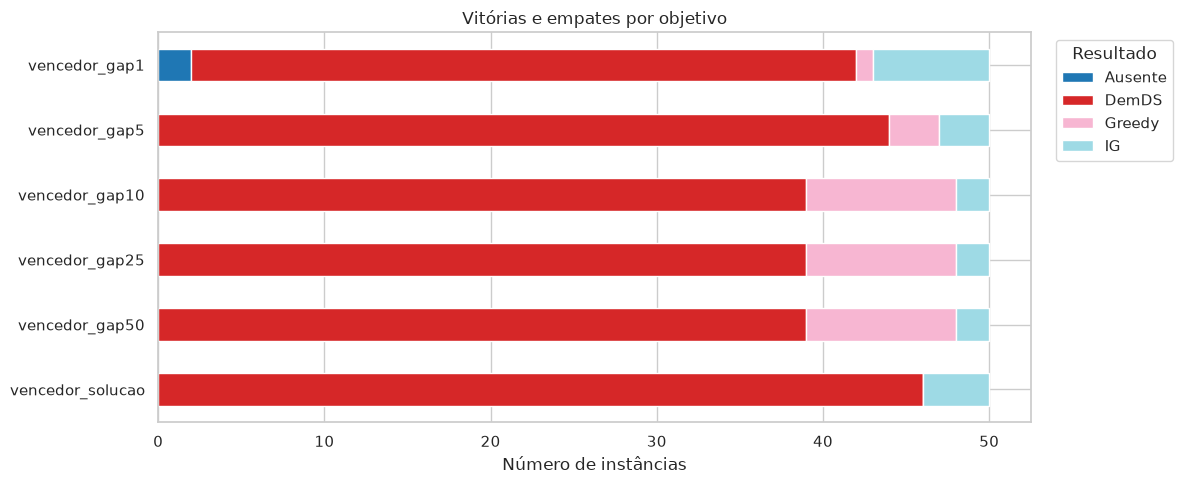

,resposta,n,mediana,q1,q3,minimo,maximo,n_zeros
0,gap_otimo_pct,50,0,0,0.0214455,0,1.32441,32
1,fracao_solucao,50,0.162533,0.114491,0.197612,0.0154361,0.306423,0


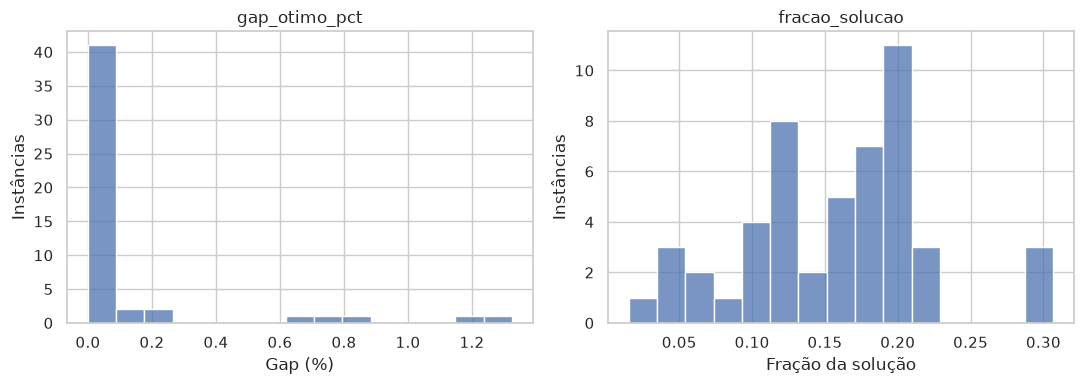

In [7]:
winner_rows, credit_rows = [], []
for target in CLASS_TARGETS:
    status_col = "status_" + target
    participants_col = target.replace("vencedor_", "participantes_")
    labels = base[target].fillna("Ausente")
    counts = labels.value_counts(dropna=False)
    for label, count in counts.items():
        winner_rows.append({"objetivo": target, "vencedor": label, "n": count,
                            "pct_total_instancias": 100 * count / len(base)})
    observed = base[status_col].fillna("ausente").ne("ausente")
    denominator = int(observed.sum())
    if not denominator:
        continue
    for algorithm in ALGORITHMS:
        credits = []
        for value in base.loc[observed, participants_col]:
            members = value if isinstance(value, tuple) else tuple()
            credits.append(1 / len(members) if algorithm in members else 0.0)
        credits = np.asarray(credits)
        rng = rng_for("credito", target, algorithm)
        samples = [credits[rng.integers(0, len(credits), len(credits))].mean()
                   for _ in range(N_BOOT)]
        lo, hi = percentile_interval(samples)
        credit_rows.append({"objetivo": target, "algoritmo": algorithm,
                            "n_instancias_com_informacao": denominator,
                            "credito_total": credits.sum(), "proporcao_credito": credits.mean(),
                            "ic95_inf": lo, "ic95_sup": hi,
                            "n_empates_sem_participantes": int(labels.eq("Empate").sum())})

winner_counts = save_table(winner_rows, "frequencias_vencedores")
win_credits = save_table(credit_rows, "creditos_vitoria_ic95")
if not winner_counts.empty:
    matrix = winner_counts.pivot(index="objetivo", columns="vencedor", values="n").fillna(0)
    matrix = matrix.reindex(CLASS_TARGETS)
    ax = matrix.plot.barh(stacked=True, figsize=(12, 5), colormap="tab20")
    ax.set(xlabel="Número de instâncias", ylabel="", title="Vitórias e empates por objetivo")
    ax.legend(title="Resultado", bbox_to_anchor=(1.02, 1), loc="upper left")
    finish_figure(ax.figure, "vencedores_por_objetivo")

quality_rows = []
for target in ["gap_otimo_pct", "fracao_solucao"]:
    values = base[target].dropna()
    quality_rows.append({"resposta": target, "n": len(values),
                         "mediana": values.median(), "q1": values.quantile(.25),
                         "q3": values.quantile(.75), "minimo": values.min(),
                         "maximo": values.max(), "n_zeros": int(values.eq(0).sum())})
save_table(quality_rows, "resumo_qualidade")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, target in zip(axes, ["gap_otimo_pct", "fracao_solucao"]):
    values = base[target].dropna()
    if len(values):
        sns.histplot(values, bins=min(15, max(1, values.nunique())), ax=ax)
    else:
        ax.text(.5, .5, "Sem referências válidas", ha="center", transform=ax.transAxes)
    ax.set(title=target, xlabel="Gap (%)" if target == "gap_otimo_pct" else "Fração da solução",
           ylabel="Instâncias")
finish_figure(fig, "qualidade_solucao")


## 5. Tempos por gap

melhores_tempos_full contém o tempo selecionado como melhor em cada gap.
As curvas abaixo descrevem esse resumo e não fornecem o tempo de cada algoritmo.
ECDFs, medianas e ICs são condicionados a tempos observados; os números de alvos não
atingidos e de registros ausentes aparecem separadamente. Se houver censura, a mediana
dos casos observados pode ser otimista e não substitui uma análise de sobrevivência.
Sem duração e indicador de censura por execução, não se estima Kaplan–Meier.

Se os arquivos registram mínimos entre seeds, estas análises descrevem esses mínimos;
não é possível recuperar a média ou a dispersão entre seeds a partir deles.


,gap,n_observados,n_nao_atingidos,n_ausentes,mediana_s,q1_s,q3_s,p90_s,ic95_mediana_inf,ic95_mediana_sup
0,50,50,0,0,0.345035,0.0528868,2.00194,4.73939,0.108047,0.774615
1,25,50,0,0,0.345035,0.0528868,2.00194,4.73939,0.0969951,0.774615
2,10,50,0,0,0.376095,0.0528868,2.00194,4.73939,0.108888,0.785503
3,5,50,0,0,0.376095,0.0559428,2.33913,6.38448,0.0969951,0.90655
4,1,48,0,2,0.406257,0.0653587,4.43674,12.911,0.0937534,0.90655


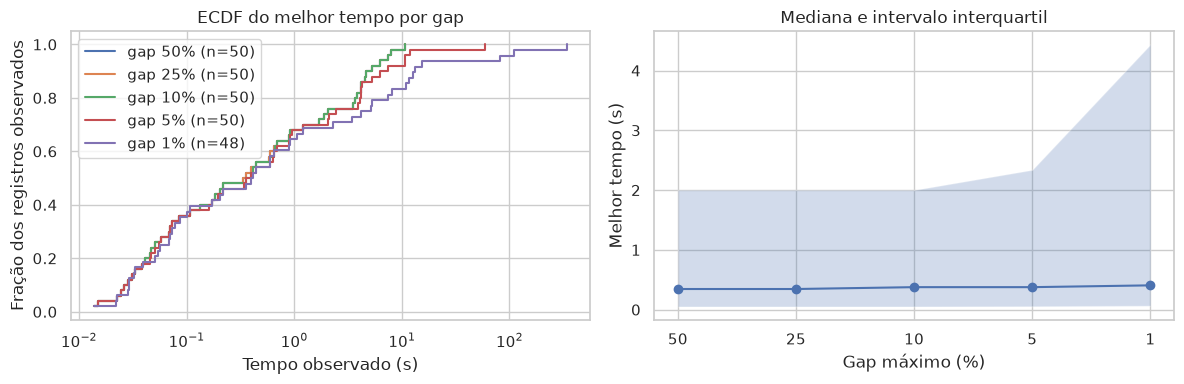

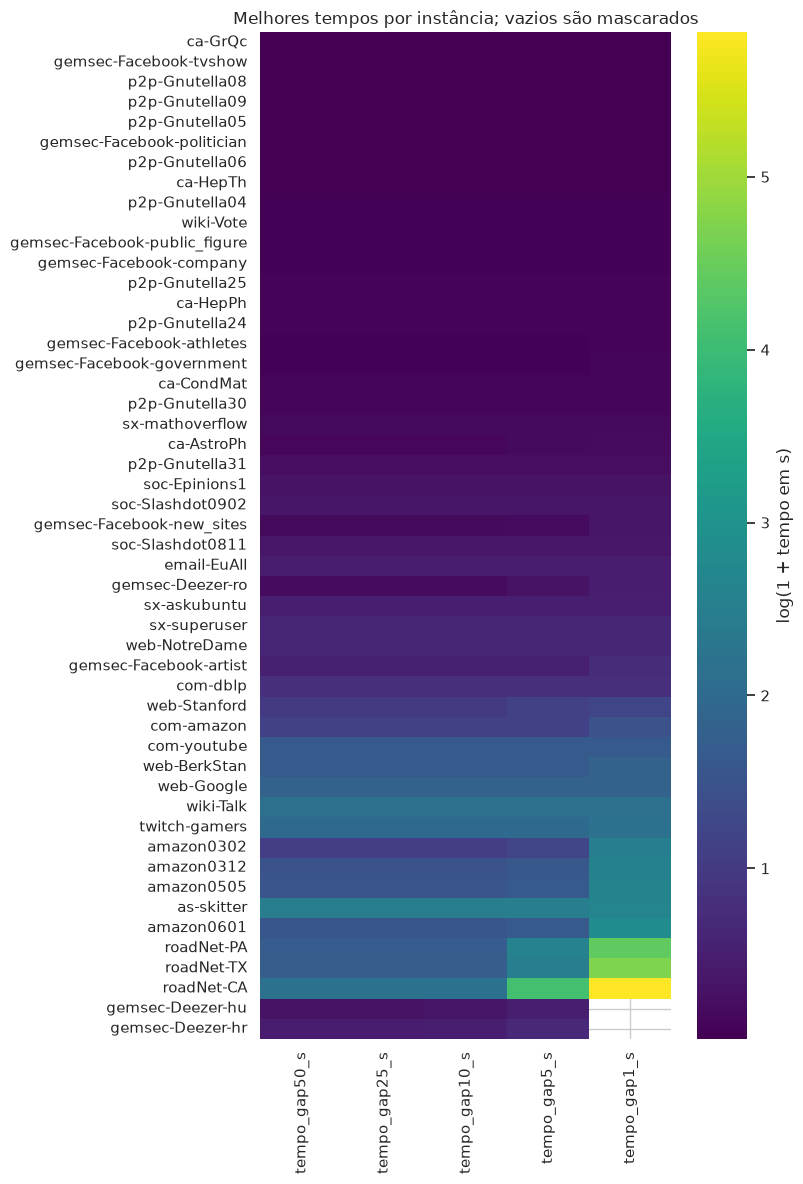

""


In [8]:
time_rows = []
for gap in GAPS:
    values = base[f"tempo_gap{gap}_s"].dropna().to_numpy(float)
    statuses = base[f"status_tempo_gap{gap}"]
    rng = rng_for("tempo_mediano", gap)
    boot = [np.median(values[rng.integers(0, len(values), len(values))])
            for _ in range(N_BOOT)] if len(values) else []
    lo, hi = percentile_interval(boot)
    time_rows.append({
        "gap": gap, "n_observados": len(values),
        "n_nao_atingidos": int(statuses.eq("nao_atingido").sum()),
        "n_ausentes": int(statuses.eq("ausente").sum()),
        "mediana_s": np.median(values) if len(values) else np.nan,
        "q1_s": np.quantile(values, .25) if len(values) else np.nan,
        "q3_s": np.quantile(values, .75) if len(values) else np.nan,
        "p90_s": np.quantile(values, .90) if len(values) else np.nan,
        "ic95_mediana_inf": lo, "ic95_mediana_sup": hi,
    })
time_summary = save_table(time_rows, "resumo_tempos_por_gap")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for gap in GAPS:
    values = np.sort(base[f"tempo_gap{gap}_s"].dropna().to_numpy(float))
    if len(values):
        axes[0].step(values, np.arange(1, len(values) + 1) / len(values), where="post",
                     label=f"gap {gap}% (n={len(values)})")
axes[0].set(xlabel="Tempo observado (s)", ylabel="Fração dos registros observados",
            title="ECDF do melhor tempo por gap")
positive = base[[f"tempo_gap{g}_s" for g in GAPS]].to_numpy().ravel()
positive = positive[np.isfinite(positive) & (positive > 0)]
if len(positive):
    axes[0].set_xscale("symlog", linthresh=max(float(positive.min()) / 10, 1e-9))
if axes[0].lines:
    axes[0].legend()
position = np.arange(len(GAPS))
med = time_summary["mediana_s"].to_numpy()
axes[1].plot(position, med, marker="o")
axes[1].fill_between(position, time_summary["q1_s"], time_summary["q3_s"], alpha=.25)
axes[1].set(xticks=position, xticklabels=[str(g) for g in GAPS], xlabel="Gap máximo (%)",
            ylabel="Melhor tempo (s)", title="Mediana e intervalo interquartil")
finish_figure(fig, "tempos_ecdf_e_medianas")

heat = base.set_index("instancia")[[f"tempo_gap{g}_s" for g in GAPS]]
heat = heat.sort_values("tempo_gap1_s", na_position="last").head(MAX_HEATMAP_ROWS)
if heat.notna().any().any():
    fig, ax = plt.subplots(figsize=(8, max(4, len(heat) * .24)))
    sns.heatmap(np.log1p(heat), mask=heat.isna(), cmap="viridis",
                cbar_kws={"label": "log(1 + tempo em s)"}, ax=ax)
    ax.set(title="Melhores tempos por instância; vazios são mascarados", ylabel="")
    finish_figure(fig, "tempos_instancias_heatmap")

monotonicity = []
for row in base.itertuples():
    values = np.array([getattr(row, f"tempo_gap{g}_s") for g in GAPS])
    good = np.isfinite(values)
    if good.sum() > 1 and (np.diff(values[good]) < -1e-9).any():
        monotonicity.append({"instancia": row.instancia, "mensagem":
                            "Há alvo mais exigente com tempo menor; confira agregação, subconjuntos e relógios."})
save_table(monotonicity, "auditoria_monotonicidade_tempos", show=bool(monotonicity))


### Gráfico opcional: diferença média de tempo por gap

delta_t_full.csv é utilizado **somente nesta visualização**, separado das bases
de análise, dos testes estatísticos e das árvores.

Para cada par A−B, a barra mostra a média de t(A)−t(B): valores negativos
favorecem A e valores positivos favorecem B. A linha horizontal marca diferença zero.
Se o arquivo não existir, apenas este gráfico é omitido.


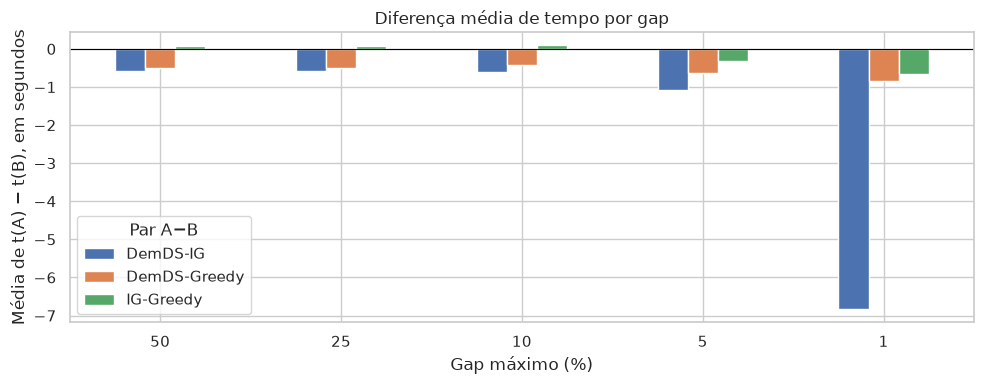

In [9]:
# Gráfico descritivo independente; nenhuma coluna é incluída nas bases estatísticas.
delta_path = RESULTS_DIR / "delta_t_full.csv"
if not delta_path.is_file():
    print("delta_t_full.csv ausente: gráfico opcional omitido.")
else:
    delta_frame = pd.read_csv(delta_path, sep=CSV_SEP, encoding="utf-8-sig")
    delta_frame.columns = delta_frame.columns.str.strip()
    delta_frame = delta_frame.loc[:, ~delta_frame.columns.str.startswith("Unnamed:")].copy()
    if "gap" not in delta_frame:
        raise ValueError("delta_t_full.csv precisa da coluna gap para o gráfico.")
    delta_frame["gap"] = pd.to_numeric(
        delta_frame["gap"].astype(str).str.replace(r"(?i)gap|%", "", regex=True).str.strip(),
        errors="coerce",
    )
    pair_columns = [c for c in delta_frame.columns if c != "gap"]
    for col in pair_columns:
        delta_frame[col] = pd.to_numeric(delta_frame[col], errors="coerce")
    if pair_columns and not delta_frame.empty:
        delta_plot = delta_frame.set_index("gap")[pair_columns].reindex(GAPS)
        if delta_plot.notna().any().any():
            ax = delta_plot.plot.bar(figsize=(10, 4), rot=0)
            ax.axhline(0, color="black", linewidth=.8)
            ax.set(
                xlabel="Gap máximo (%)", ylabel="Média de t(A) − t(B), em segundos",
                title="Diferença média de tempo por gap",
            )
            ax.legend(title="Par A−B")
            finish_figure(ax.figure, "delta_t_agregado_descritivo")


## 6. Correlações numéricas e controle descritivo do tamanho

As correlações entre topologia e desempenho são idênticas em total e cauda, pois
nenhuma dessas duas tabelas numéricas muda com o ajuste da distribuição.
Elas são calculadas **uma vez**, com escopo "comum".
Não se convertem nomes de algoritmos ou distribuições em números para calcular correlação.

Spearman mede associação monotônica. O mapa entre características ajuda a identificar
redundâncias: n, m, grau médio e densidade têm relações algébricas.
A correlação parcial é calculada nos postos, retirando a projeção sobre n e m.
Ela é somente descritiva, sem p-valor; não elimina confundimento e não tem interpretação causal.
fracao_solucao contém n no denominador: correlações com o tamanho exigem cuidado adicional.


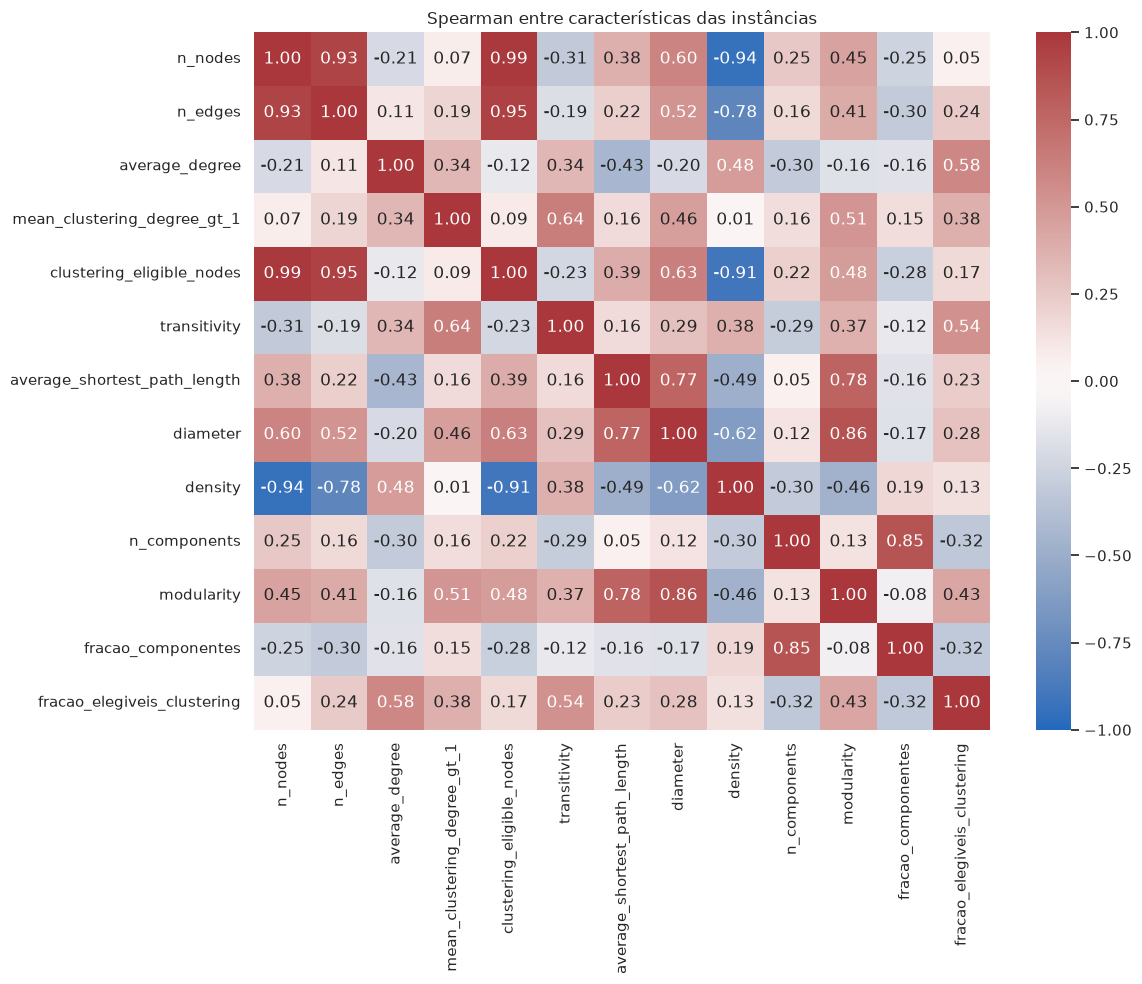

,escopo,caracteristica,resposta,n,rho,p_perm,ic95_inf,ic95_sup,status,n_parcial,rho_parcial_tamanho,status_parcial,p_holm,significativo_holm
0,comum,n_nodes,tempo_gap50_s,50,0.973109,5e-05,0.934272,0.989905,ok,50,NaN,caracteristica_e_controle,0.00455,True
1,comum,n_edges,tempo_gap50_s,50,0.977911,5e-05,0.951218,0.985768,ok,50,NaN,caracteristica_e_controle,0.00455,True
2,comum,average_degree,tempo_gap50_s,50,-0.0561345,0.70325,-0.364446,0.252174,ok,50,-0.346708,descritivo_sem_pvalor,1,False
3,comum,mean_clustering_degree_gt_1,tempo_gap50_s,50,0.106747,0.46625,-0.183302,0.390309,ok,50,-0.27156,descritivo_sem_pvalor,1,False
4,comum,clustering_eligible_nodes,tempo_gap50_s,50,0.979736,5e-05,0.947684,0.992781,ok,50,0.283122,descritivo_sem_pvalor,0.00455,True
5,comum,transitivity,tempo_gap50_s,50,-0.245714,0.0861,-0.505718,0.0791805,ok,50,-0.0157278,descritivo_sem_pvalor,1,False
6,comum,average_shortest_path_length,tempo_gap50_s,50,0.290276,0.0413,-0.0376643,0.570782,ok,50,-0.0552456,descritivo_sem_pvalor,1,False
7,comum,diameter,tempo_gap50_s,50,0.545609,0.00015,0.2751,0.774262,ok,50,-0.179017,descritivo_sem_pvalor,0.00915,True
8,comum,density,tempo_gap50_s,50,-0.866411,5e-05,-0.932291,-0.753151,ok,50,-0.0644833,descritivo_sem_pvalor,0.00455,True
9,comum,n_components,tempo_gap50_s,50,0.227281,0.11145,-0.0801493,0.487948,ok,50,0.164813,descritivo_sem_pvalor,1,False


91 linhas; tabela completa em correlacoes_spearman.csv.


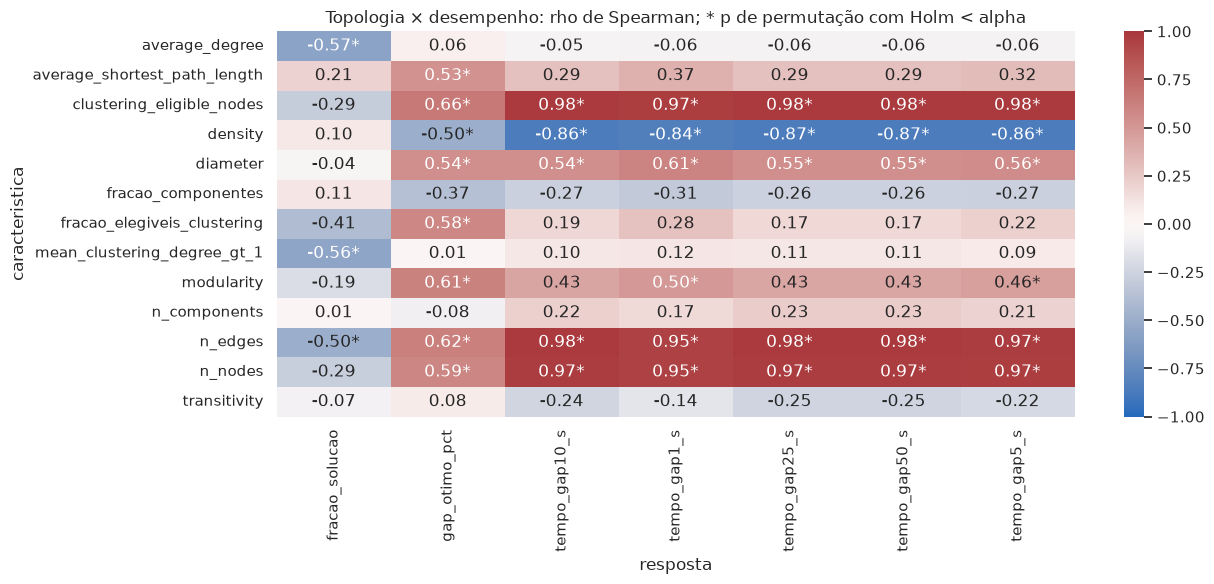

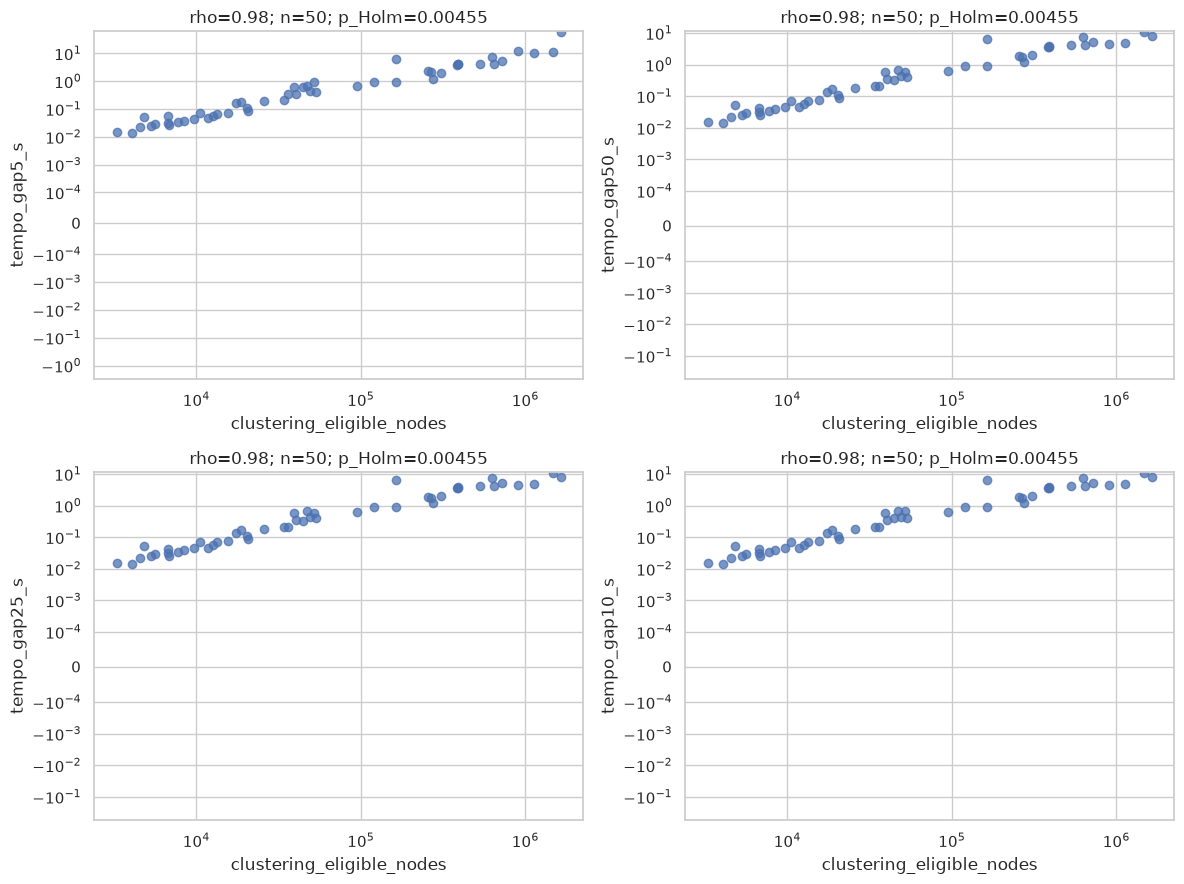

In [10]:
feature_corr = base[NUMERIC_FEATURES].corr(method="spearman")
save_table(feature_corr.rename_axis("caracteristica").reset_index(), "spearman_entre_metricas", show=False)
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(feature_corr, vmin=-1, vmax=1, cmap="vlag", center=0, annot=True, fmt=".2f", ax=ax)
ax.set_title("Spearman entre características das instâncias")
finish_figure(fig, "spearman_metricas")

correlation_rows = []
for target in NUMERIC_TARGETS:
    for feature in NUMERIC_FEATURES:
        row = {"escopo": "comum", "caracteristica": feature, "resposta": target}
        row.update(spearman_test(base[feature].to_numpy(float),
                                 base[target].to_numpy(float), (feature, target)))
        row.update(partial_spearman(base, feature, target))
        correlation_rows.append(row)
correlations = adjust_holm(pd.DataFrame(correlation_rows))
save_table(correlations, "correlacoes_spearman")
valid_correlations = correlations[correlations["status"].eq("ok")]
if not valid_correlations.empty:
    corr_heat = correlations.pivot(index="caracteristica", columns="resposta", values="rho")
    sig_heat = correlations.pivot(index="caracteristica", columns="resposta", values="p_holm")
    annotation = corr_heat.copy().astype(object)
    for i in corr_heat.index:
        for j in corr_heat.columns:
            value = corr_heat.loc[i, j]
            annotation.loc[i, j] = "" if pd.isna(value) else f"{value:.2f}" + (
                "*" if pd.notna(sig_heat.loc[i, j]) and sig_heat.loc[i, j] < ALPHA else ""
            )
    fig, ax = plt.subplots(figsize=(13, max(6, len(corr_heat) * .45)))
    sns.heatmap(corr_heat, annot=annotation, fmt="", cmap="vlag", vmin=-1, vmax=1,
                center=0, ax=ax)
    ax.set_title("Topologia × desempenho: rho de Spearman; * p de permutação com Holm < alpha")
    finish_figure(fig, "spearman_topologia_desempenho")

    # Escolha visual exploratória, sem novo teste de significância.
    top = valid_correlations.assign(abs_rho=lambda x: x["rho"].abs()).nlargest(4, "abs_rho")
    fig, axes = plt.subplots(2, 2, figsize=(12, 9))
    for ax, row in zip(axes.ravel(), top.itertuples()):
        subset = base[["instancia", row.caracteristica, row.resposta]].dropna()
        ax.scatter(subset[row.caracteristica], subset[row.resposta], alpha=.75)
        ax.set(xlabel=row.caracteristica, ylabel=row.resposta,
               title=f"rho={row.rho:.2f}; n={row.n}; p_Holm={row.p_holm:.3g}")
        if (subset[row.caracteristica] > 0).all() and subset[row.caracteristica].max() / subset[row.caracteristica].min() > 100:
            ax.set_xscale("log")
        if row.resposta.startswith("tempo_"):
            ax.set_yscale("symlog", linthresh=1e-4)
    for ax in axes.ravel()[len(top):]:
        ax.set_visible(False)
    finish_figure(fig, "dispersoes_correlacoes_exploratorias")


## 7. Distribuição escolhida versus vencedor

Cada escopo é analisado separadamente, com uma linha por instância.
O teste permuta o vencedor entre as instâncias, preservando as frequências das categorias.
Isso evita depender da aproximação do qui-quadrado quando há células pequenas.
V de Cramér mede força de associação sem sinal e pode ser inflado em amostras pequenas.

Empates conhecidos e desconhecidos aparecem como categorias explícitas; não se
explode uma instância em várias linhas para contar cada participante como independente.
Sem vencedor ou sem distribuição, a linha fica fora do teste, com n informado.
O nome da distribuição escolhida não mede a qualidade do ajuste: este CSV não contém
AIC, KS, fração da cauda ou diagnósticos suficientes para avaliar o fitting.


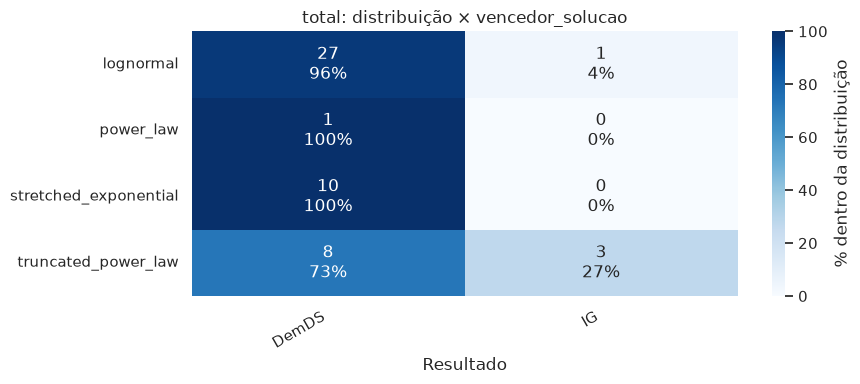

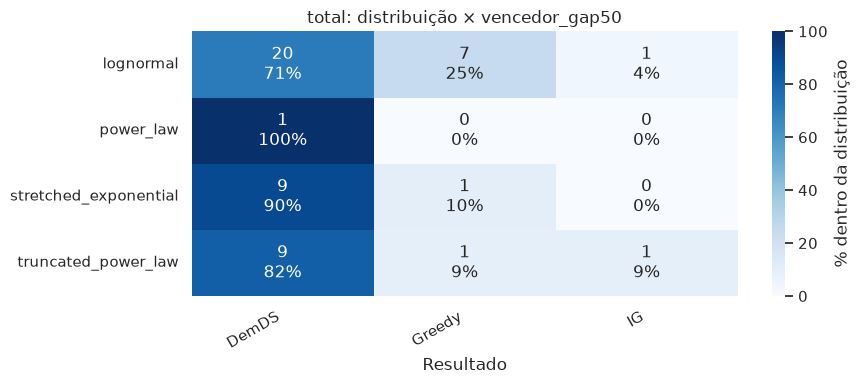

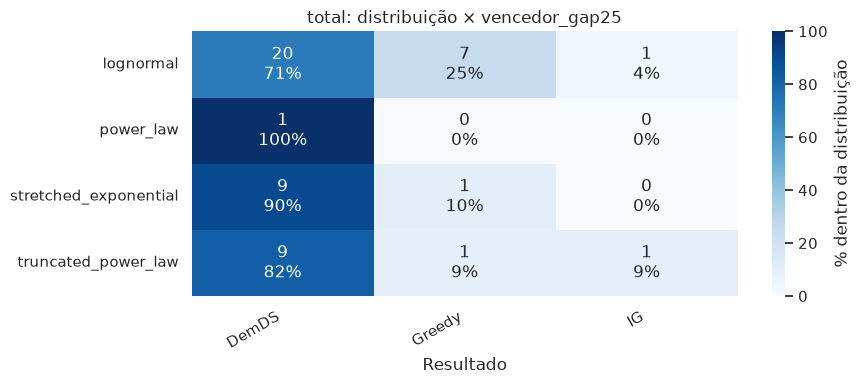

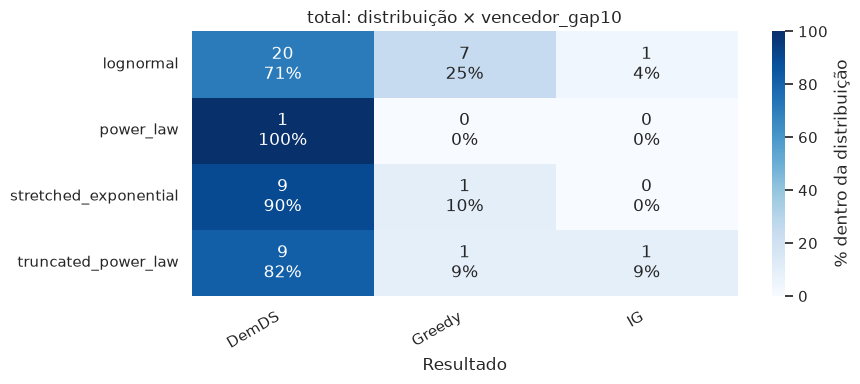

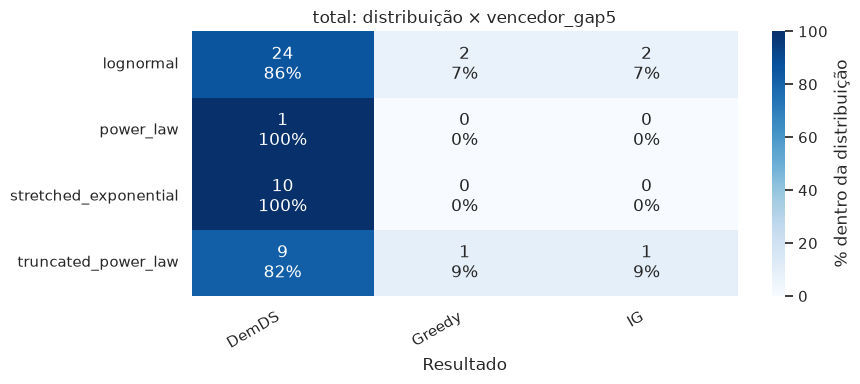

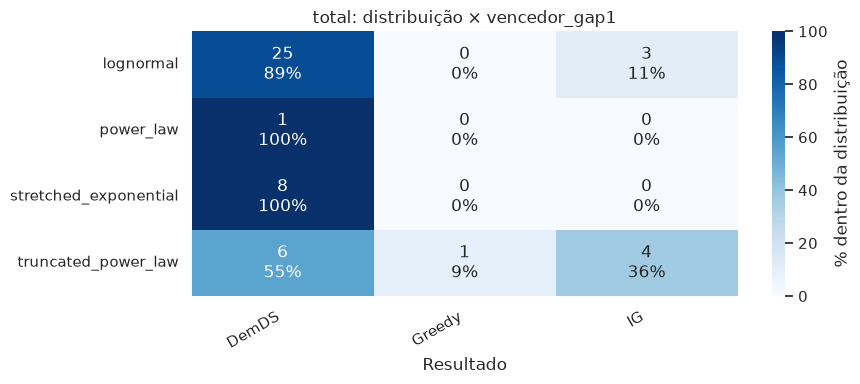

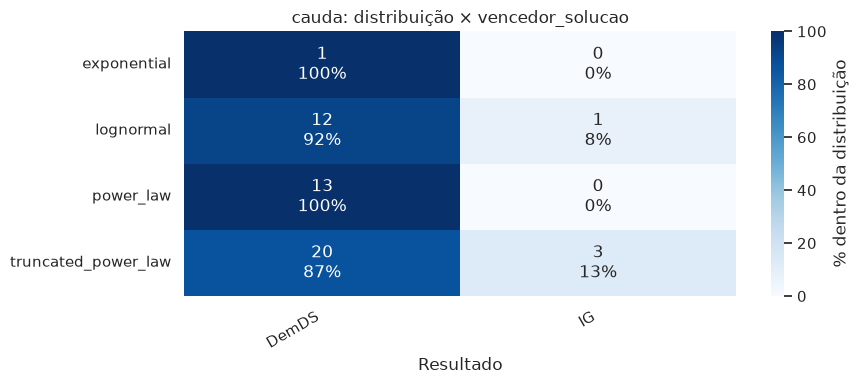

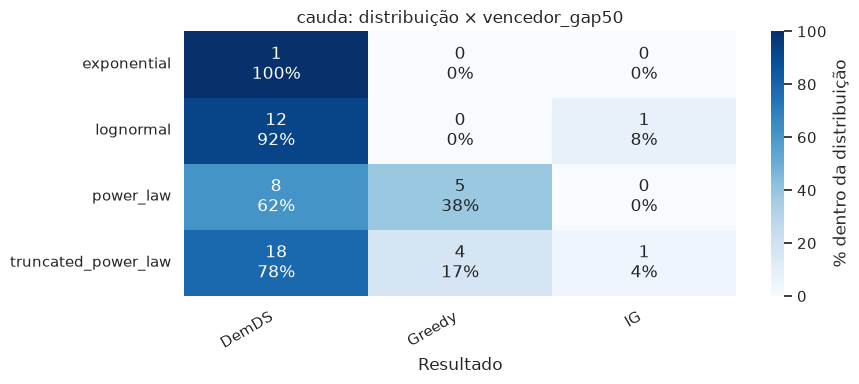

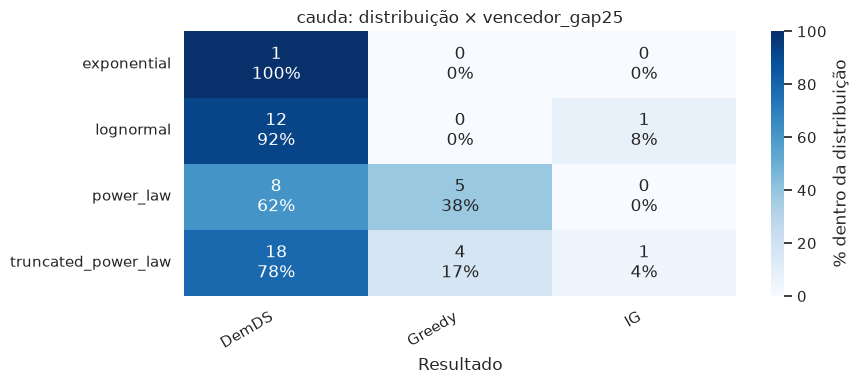

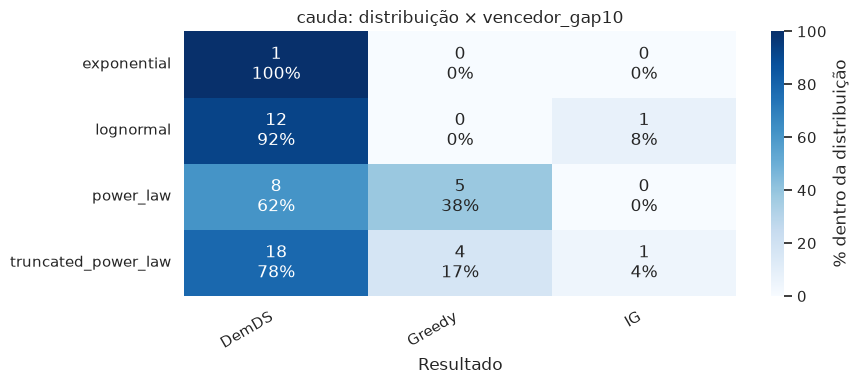

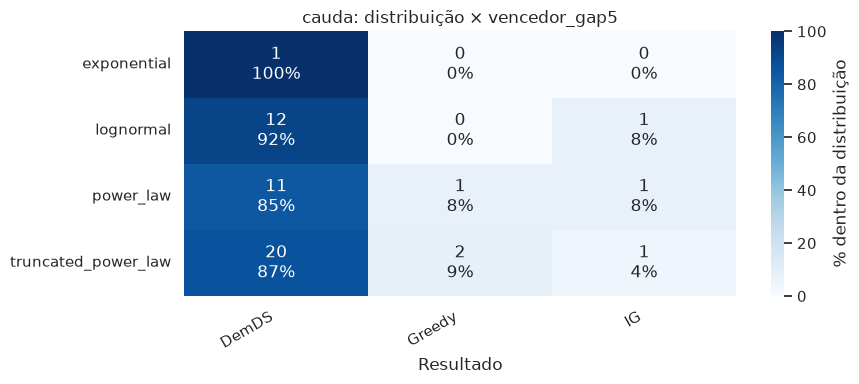

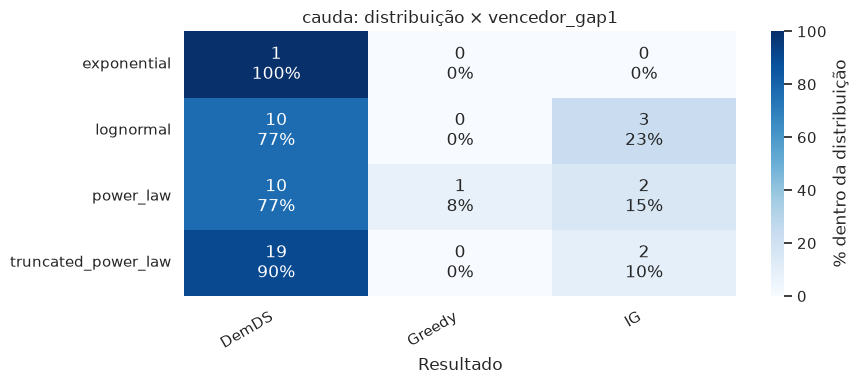

,escopo,resposta,n,chi2,v_cramer,p_perm,min_frequencia_esperada,status,p_holm,significativo_holm
0,total,vencedor_solucao,50,7.25402,0.380894,0.127,0.08,ok,1,False
1,total,vencedor_gap50,50,3.37066,0.183593,0.63985,0.04,ok,1,False
2,total,vencedor_gap25,50,3.37066,0.183593,0.63625,0.04,ok,1,False
3,total,vencedor_gap10,50,3.37066,0.183593,0.64035,0.04,ok,1,False
4,total,vencedor_gap5,50,2.0366,0.142709,0.7574,0.06,ok,1,False
5,total,vencedor_gap1,48,10.0547,0.323631,0.1098,0.0208333,ok,1,False
6,cauda,vencedor_solucao,50,2.01396,0.200697,0.6124,0.08,ok,1,False
7,cauda,vencedor_gap50,50,7.4136,0.272279,0.2541,0.04,ok,1,False
8,cauda,vencedor_gap25,50,7.4136,0.272279,0.25755,0.04,ok,1,False
9,cauda,vencedor_gap10,50,7.4136,0.272279,0.2568,0.04,ok,1,False


,escopo,resposta,n,chi2,v_cramer,p_perm,min_frequencia_esperada,status,p_holm,significativo_holm
0,total,vencedor_solucao,50,7.25402,0.380894,0.127,0.08,ok,1,False
1,total,vencedor_gap50,50,3.37066,0.183593,0.63985,0.04,ok,1,False
2,total,vencedor_gap25,50,3.37066,0.183593,0.63625,0.04,ok,1,False
3,total,vencedor_gap10,50,3.37066,0.183593,0.64035,0.04,ok,1,False
4,total,vencedor_gap5,50,2.0366,0.142709,0.7574,0.06,ok,1,False
5,total,vencedor_gap1,48,10.0547,0.323631,0.1098,0.0208333,ok,1,False
6,cauda,vencedor_solucao,50,2.01396,0.200697,0.6124,0.08,ok,1,False
7,cauda,vencedor_gap50,50,7.4136,0.272279,0.2541,0.04,ok,1,False
8,cauda,vencedor_gap25,50,7.4136,0.272279,0.25755,0.04,ok,1,False
9,cauda,vencedor_gap10,50,7.4136,0.272279,0.2568,0.04,ok,1,False


In [11]:
categorical_rows = []
for scope, frame in bases.items():
    for target in CLASS_TARGETS:
        valid = frame["status_" + target].isin(["unico", "empate"])
        subset = frame.loc[valid, ["distribuicao", target]].dropna()
        row = {"escopo": scope, "resposta": target}
        row.update(contingency_test(subset["distribuicao"], subset[target], (scope, target)))
        categorical_rows.append(row)
        if subset.empty:
            continue
        table = pd.crosstab(subset["distribuicao"], subset[target])
        save_table(table.rename_axis("distribuicao").reset_index(),
                   f"contingencia_{scope}_{target}", show=False)
        proportions = table.div(table.sum(axis=1), axis=0) * 100
        fig, ax = plt.subplots(figsize=(max(9, len(table.columns) * 1.8), max(4, len(table) * .65)))
        labels = table.astype(str) + "\n" + proportions.map(lambda x: f"{x:.0f}%")
        sns.heatmap(proportions, annot=labels, fmt="", vmin=0, vmax=100, cmap="Blues",
                    cbar_kws={"label": "% dentro da distribuição"}, ax=ax)
        ax.set(title=f"{scope}: distribuição × {target}", xlabel="Resultado", ylabel="")
        ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha="right")
        finish_figure(fig, f"contingencia_{scope}_{target}")
categorical_associations = adjust_holm(pd.DataFrame(categorical_rows))
save_table(categorical_associations, "associacoes_distribuicao_vencedor")


## 8. Comparações numéricas entre grupos

Duas perguntas distintas:
1. Quais características topológicas diferenciam os grupos de instâncias em que cada
algoritmo vence? Essa análise é comum aos dois escopos.
2. Como tempos e gaps variam entre as distribuições escolhidas? Essa análise é separada
para total e cauda.

Uma propriedade topológica diferente entre grupos vencedores não prova superioridade
de um algoritmo naquele regime. Não há aqui medidas de desempenho dos algoritmos
perdedores. Grupos com menos de MIN_N_GROUP casos não são descartados silenciosamente:
o teste fica marcado como insuficiente. Nas comparações de pares, Cliff e o p de
permutação dos postos são calculados para todos os pares planejados e Holm é aplicado
à família inteira; não se escolhem pares pelo p-valor observado.

Parâmetros de distribuições são exportados em tabela longa. Não se compara, por exemplo,
alpha de uma power law com sigma de uma lognormal como se fossem a mesma variável.


,escopo,analise,variavel_numerica,agrupamento,n,n_grupos,menor_grupo,h,eta2_h,p_perm,status,p_holm,significativo_holm
0,comum,topologia_por_vencedor,n_nodes,vencedor_solucao,50,2,4,0.86445,0,0.37265,ok,1,False
1,comum,topologia_por_vencedor,n_edges,vencedor_solucao,50,2,4,1.39258,0.00817882,0.2611,ok,1,False
2,comum,topologia_por_vencedor,average_degree,vencedor_solucao,50,2,4,0.0626598,0,0.82775,ok,1,False
3,comum,topologia_por_vencedor,mean_clustering_degree_gt_1,vencedor_solucao,50,2,4,1.1509,0.00314365,0.3084,ok,1,False
4,comum,topologia_por_vencedor,clustering_eligible_nodes,vencedor_solucao,50,2,4,1.2289,0.00476876,0.29215,ok,1,False
5,comum,topologia_por_vencedor,transitivity,vencedor_solucao,50,2,4,0.86445,0,0.382,ok,1,False
6,comum,topologia_por_vencedor,average_shortest_path_length,vencedor_solucao,50,2,4,1.30946,0.00644714,0.27425,ok,1,False
7,comum,topologia_por_vencedor,diameter,vencedor_solucao,50,2,4,2.89915,0.0395657,0.0971,ok,1,False
8,comum,topologia_por_vencedor,density,vencedor_solucao,50,2,4,0.250639,0,0.6348,ok,1,False
9,comum,topologia_por_vencedor,n_components,vencedor_solucao,50,2,4,0.277651,0,0.62465,ok,1,False


92 linhas; tabela completa em comparacoes_grupos_kruskal.csv.


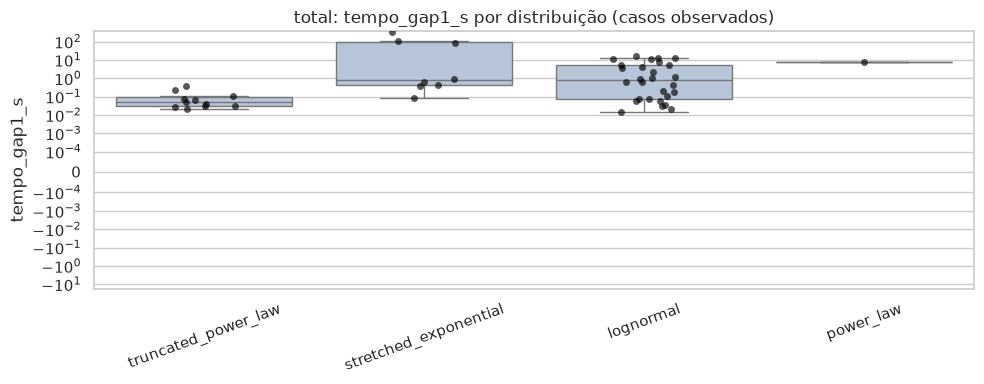

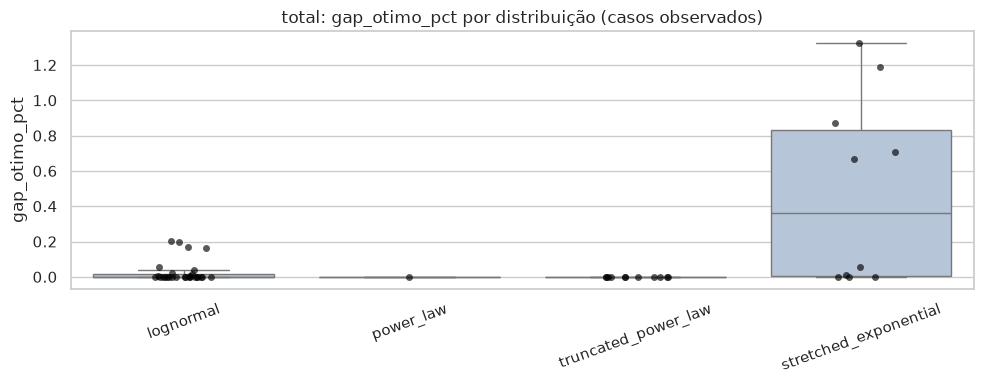

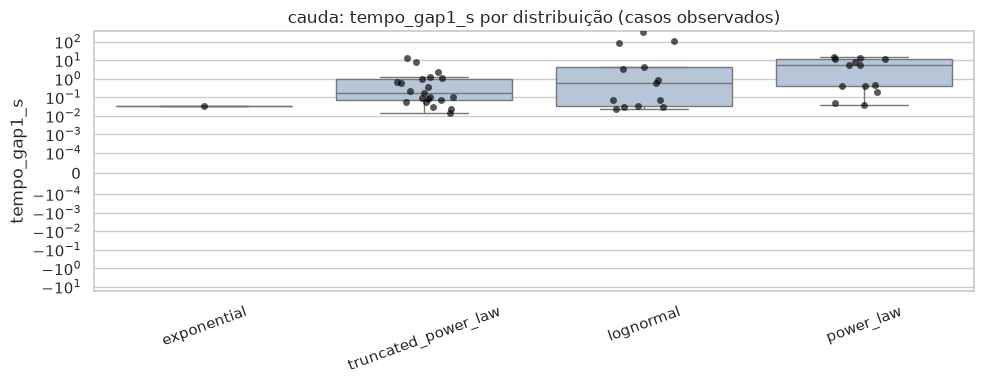

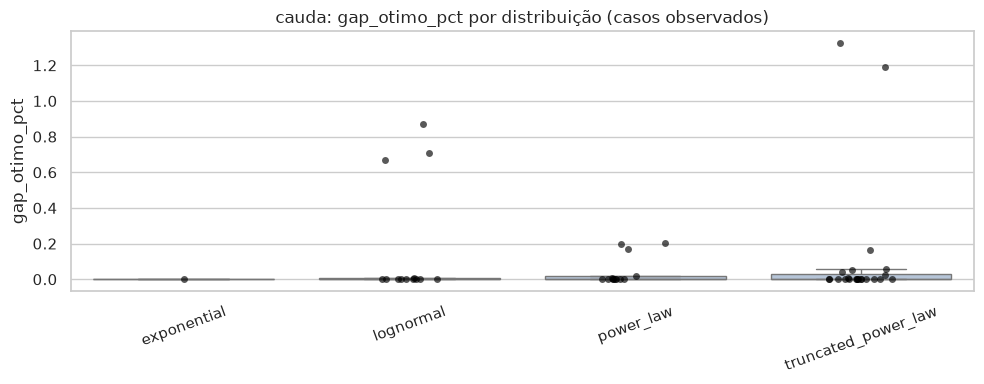

,escopo,distribuicao,parametro,n,mediana,minimo,maximo
0,cauda,exponential,Lambda,1,0.138778,0.138778,0.138778
1,cauda,lognormal,mu,13,-227.454,-844.326,1.19068
2,cauda,lognormal,sigma,13,6.14793,0.141391,22.6468
3,cauda,power_law,alpha,13,3.3776,2.12321,4.58329
4,cauda,truncated_power_law,Lambda,23,0.00506546,1.00623e-05,0.0391985
5,cauda,truncated_power_law,alpha,23,2.52255,1.56942,4.33665
6,total,lognormal,mu,28,1.55506,-844.326,3.3958
7,total,lognormal,sigma,28,1.16525,0.482386,22.6468
8,total,power_law,alpha,1,2.45886,2.45886,2.45886
9,total,stretched_exponential,Lambda,10,0.318244,0.0470791,205.803


In [12]:
group_rows, posthoc_rows = [], []


def register_group_test(frame, numeric_col, grouping_col, scope, kind):
    subset = frame[[numeric_col, grouping_col]].dropna()
    key = (scope, kind, numeric_col, grouping_col)
    row = {"escopo": scope, "analise": kind, "variavel_numerica": numeric_col,
           "agrupamento": grouping_col}
    row.update(kruskal_permutation(subset[numeric_col], subset[grouping_col], key))
    group_rows.append(row)
    if RUN_POSTHOC:
        for pair in pairwise_cliff(subset[numeric_col], subset[grouping_col], key):
            posthoc_rows.append({"escopo": scope, "analise": kind,
                                 "variavel_numerica": numeric_col,
                                 "agrupamento": grouping_col, **pair})


for target in CLASS_TARGETS:
    winner_subset = base.loc[base["status_" + target].eq("unico")]
    for feature in NUMERIC_FEATURES:
        register_group_test(winner_subset, feature, target, "comum", "topologia_por_vencedor")
for scope, frame in bases.items():
    for target in NUMERIC_TARGETS:
        register_group_test(frame, target, "distribuicao", scope, "desempenho_por_distribuicao")

numeric_groups = adjust_holm(pd.DataFrame(group_rows))
save_table(numeric_groups, "comparacoes_grupos_kruskal")
posthoc = adjust_holm(pd.DataFrame(posthoc_rows))
save_table(posthoc, "comparacoes_pares_cliff", show=False)

for scope, frame in bases.items():
    for target in ["tempo_gap1_s", "gap_otimo_pct"]:
        subset = frame[["distribuicao", target]].dropna()
        if subset.empty:
            continue
        order = subset.groupby("distribuicao")[target].median().sort_values().index
        fig, ax = plt.subplots(figsize=(10, 4))
        sns.boxplot(data=subset, x="distribuicao", y=target, order=order, ax=ax,
                    color="lightsteelblue", showfliers=False)
        sns.stripplot(data=subset, x="distribuicao", y=target, order=order,
                      jitter=.15, color="black", alpha=.65, ax=ax)
        ax.tick_params(axis="x", rotation=20)
        ax.set(title=f"{scope}: {target} por distribuição (casos observados)", xlabel="")
        if target.startswith("tempo_"):
            ax.set_yscale("symlog", linthresh=1e-4)
        finish_figure(fig, f"boxplot_{scope}_{target}")

if not parameter_table.empty:
    parameter_summary = parameter_table.groupby(
        ["escopo", "distribuicao", "parametro"]
    )["valor"].agg(n="size", mediana="median", minimo="min", maximo="max").reset_index()
    save_table(parameter_summary, "resumo_parametros_por_familia")


## 9. Concordância entre total e cauda

Esta comparação é pareada por instância. Kappa compara a concordância observada com
a esperada a partir das frequências marginais. Não demonstra que um escopo esteja
certo ou produza um ajuste melhor. Modelos escolhidos em domínios diferentes podem
diferir legitimamente. O IC é obtido reamostrando pares de uma mesma instância.


,n_pares,n_mudaram,concordancia,ic95_concordancia_inf,ic95_concordancia_sup,kappa,ic95_kappa_inf,ic95_kappa_sup
0,50,42,0.16,0.06,0.26,-0.122995,-0.273345,0.0186334


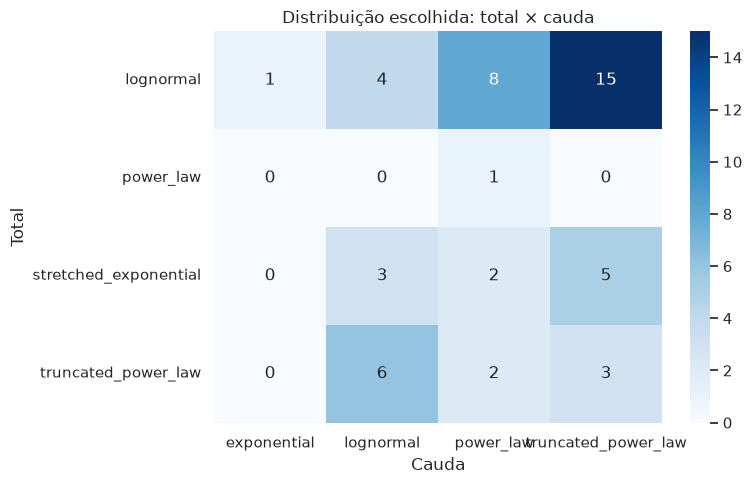

In [13]:
scope_pairs = bases["total"][["instancia", "distribuicao"]].rename(
    columns={"distribuicao": "distribuicao_total"}
).merge(
    bases["cauda"][["instancia", "distribuicao"]].rename(
        columns={"distribuicao": "distribuicao_cauda"}
    ), on="instancia", validate="one_to_one"
).dropna()
save_table(scope_pairs, "pares_total_cauda", show=False)
if not scope_pairs.empty:
    a = scope_pairs["distribuicao_total"].to_numpy()
    b = scope_pairs["distribuicao_cauda"].to_numpy()
    labels = np.unique(np.r_[a, b])

    def safe_kappa(x, y):
        if len(np.unique(np.r_[x, y])) < 2:
            return np.nan
        return cohen_kappa_score(x, y, labels=labels)

    rng = rng_for("concordancia")
    agree_boot, kappa_boot = [], []
    for _ in range(N_BOOT):
        index = rng.integers(0, len(a), len(a))
        agree_boot.append(np.mean(a[index] == b[index]))
        value = safe_kappa(a[index], b[index])
        if np.isfinite(value):
            kappa_boot.append(value)
    agree_lo, agree_hi = percentile_interval(agree_boot)
    kappa_lo, kappa_hi = percentile_interval(kappa_boot)
    save_table([{
        "n_pares": len(a), "n_mudaram": int(np.sum(a != b)),
        "concordancia": np.mean(a == b), "ic95_concordancia_inf": agree_lo,
        "ic95_concordancia_sup": agree_hi, "kappa": safe_kappa(a, b),
        "ic95_kappa_inf": kappa_lo, "ic95_kappa_sup": kappa_hi,
    }], "concordancia_total_cauda")
    transition = pd.crosstab(scope_pairs["distribuicao_total"], scope_pairs["distribuicao_cauda"])
    fig, ax = plt.subplots(figsize=(8, 5))
    sns.heatmap(transition, annot=True, fmt="d", cmap="Blues", ax=ax)
    ax.set(title="Distribuição escolhida: total × cauda", xlabel="Cauda", ylabel="Total")
    finish_figure(fig, "transicoes_total_cauda")
else:
    note("concordância", "Sem pares válidos de distribuição total/cauda.")


## 10. Árvores de decisão: avaliação fora da amostra

Há uma tarefa por resposta, sem empilhar os gaps como instâncias independentes.
Para cada tarefa são avaliadas três entradas: somente métricas, somente distribuição
e métricas + distribuição. Todas usam os mesmos casos e as mesmas divisões de validação
em total e cauda. Distribuição ausente entra como categoria "não_informada".

- Classificação: árvore pequena com peso balanceado, comparada à classe majoritária
  do treino. Métricas: acurácia balanceada, macro F1 e acurácia.
- Regressão: árvore pequena que usa perda absoluta, comparada à mediana do treino.
  Tempos são aprendidos em log(1+t) e invertidos para segundos na avaliação.
  Métricas: MAE nas unidades originais e R².
- Imputação e codificação são ajustadas somente no treino de cada divisão.
  Identificador, parâmetros pós-seleção do fitting, referência ótima, solução obtida,
  orçamento e outras respostas não entram nas características.
- Acurácia balanceada é calculada nas predições fora da amostra reunidas, não no treino.
  Não se trata cada fold como uma réplica independente para produzir p-valores.
- Empates são excluídos dos modelos por padrão e continuam nas análises descritivas.
  Classes raras não são apagadas para viabilizar a classificação: a tarefa é omitida
  quando não há pelo menos dois casos em cada classe.
- Cada instância fica fora do treino uma vez: CV estratificada na classificação
  e K-fold na regressão. A junção por nome é automática e não exige mapeamento
  de famílias. As bases de total/cauda nunca são empilhadas.

A importância é obtida por permutação no teste de cada fold, antes do reajuste
ilustrativo. Na classificação, sua unidade é queda de macro F1; na regressão,
aumento de MAE. As dispersões entre folds não são ICs de inferência.
Características correlacionadas podem dividir ou mascarar sua importância.

O melhor tempo é um alvo selecionado entre algoritmos. Prever esse alvo não equivale
a prever o tempo individual de DemDS, IG ou Greedy, nem mede a economia de um seletor.
Os CSVs não permitem calcular regret em tempo ou speedup por instância.


In [14]:
VARIANTS = {
    "metricas": (MODEL_FEATURES, []),
    "distribuicao": ([], ["distribuicao"]),
    "metricas_e_distribuicao": (MODEL_FEATURES, ["distribuicao"]),
}
MODEL_SCORES, OOF_ROWS, IMPORTANCE_ROWS, FOLD_ROWS = [], [], [], []
FITTED_EXAMPLES = {}


def make_pipeline(numeric, categorical, kind, target):
    transformers = []
    if numeric:
        transformers.append(("num", SimpleImputer(strategy="median", keep_empty_features=True), numeric))
    if categorical:
        transformers.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False),
                             categorical))
    preprocess = ColumnTransformer(transformers, remainder="drop", verbose_feature_names_out=True)
    if kind == "classificacao":
        estimator = DecisionTreeClassifier(
            max_depth=TREE_MAX_DEPTH, min_samples_leaf=TREE_MIN_SAMPLES_LEAF,
            class_weight="balanced", random_state=SEED,
        )
    else:
        estimator = DecisionTreeRegressor(
            criterion="absolute_error", max_depth=TREE_MAX_DEPTH,
            min_samples_leaf=TREE_MIN_SAMPLES_LEAF, random_state=SEED,
        )
        if target.startswith("tempo_"):
            estimator = TransformedTargetRegressor(
                regressor=estimator, func=np.log1p, inverse_func=np.expm1,
            )
    return Pipeline([("preprocess", preprocess), ("estimator", estimator)])


def task_data(frame, target, kind):
    if kind == "classificacao":
        accepted = ["unico", "empate"] if INCLUDE_TIES_IN_MODELS else ["unico"]
        subset = frame.loc[frame["status_" + target].isin(accepted) & frame[target].notna()].copy()
    else:
        subset = frame.loc[frame[target].notna() & np.isfinite(frame[target])].copy()
    return subset.sort_values("instancia").reset_index(drop=True)


def task_splits(subset, target, kind):
    if len(subset) < MIN_N_MODEL:
        return None, f"n={len(subset)} < MIN_N_MODEL={MIN_N_MODEL}"
    if subset[target].nunique() < 2:
        return None, "resposta constante"
    if kind == "classificacao":
        smallest_class = int(subset[target].value_counts().min())
        if smallest_class < 2:
            return None, "classe com menos de dois casos; nenhuma classe foi removida"
        nfolds = min(CV_FOLDS, smallest_class)
        return list(StratifiedKFold(n_splits=nfolds, shuffle=True, random_state=SEED)
                    .split(subset, subset[target])), "instancias_estratificadas"
    nfolds = min(CV_FOLDS, len(subset))
    return list(KFold(n_splits=nfolds, shuffle=True, random_state=SEED).split(subset)), "instancias"


def evaluate_task(frame, scope, target, kind):
    solution_related = target in {"vencedor_solucao", "gap_otimo_pct"}
    if MIXED_BUDGETS and solution_related and not ALLOW_MIXED_BUDGETS_MODELS:
        MODEL_NOTES.append({"escopo": scope, "resposta": target,
                            "motivo": "orçamentos distintos; estratifique por limite_s"})
        return
    subset = task_data(frame, target, kind)
    splits, cv_kind = task_splits(subset, target, kind)
    if splits is None:
        MODEL_NOTES.append({"escopo": scope, "resposta": target, "n": len(subset), "motivo": cv_kind})
        return
    y = subset[target].to_numpy()
    classes = sorted(subset[target].unique()) if kind == "classificacao" else None
    test_counts = np.zeros(len(subset), dtype=int)
    for train, test in splits:
        if set(train) & set(test):
            raise AssertionError("Treino e teste se sobrepõem.")
        test_counts[test] += 1
    if not np.all(test_counts == 1):
        raise AssertionError("Cada instância deve ser avaliada exatamente uma vez.")

    for variant, (numeric, categorical) in VARIANTS.items():
        if not numeric and not categorical:
            continue
        features = [*numeric, *categorical]
        X = subset[features].copy()
        for col in categorical:
            X[col] = X[col].fillna("não_informada").astype(str)
        dtype = object if kind == "classificacao" else float
        oof = np.empty(len(subset), dtype=dtype)
        baseline_oof = np.empty(len(subset), dtype=dtype)
        fold_ids = np.empty(len(subset), dtype=int)
        for fold, (train, test) in enumerate(splits):
            model = make_pipeline(numeric, categorical, kind, target)
            dummy = (DummyClassifier(strategy="most_frequent") if kind == "classificacao"
                     else DummyRegressor(strategy="median"))
            model.fit(X.iloc[train], y[train])
            dummy.fit(np.zeros((len(train), 1)), y[train])
            oof[test] = model.predict(X.iloc[test])
            baseline_oof[test] = dummy.predict(np.zeros((len(test), 1)))
            fold_ids[test] = fold
            FOLD_ROWS.append({"escopo": scope, "resposta": target, "entradas": variant,
                              "fold": fold, "n_treino": len(train), "n_teste": len(test),
                              "validacao": cv_kind})
            if kind == "classificacao":
                def scorer(fitted, data, truth):
                    return f1_score(truth, fitted.predict(data), average="macro",
                                    labels=classes, zero_division=0)
            else:
                scorer = "neg_mean_absolute_error"
            importance = permutation_importance(
                model, X.iloc[test], y[test], scoring=scorer,
                n_repeats=IMPORTANCE_REPEATS, random_state=SEED + fold, n_jobs=1,
            )
            for feature, mean, std in zip(features, importance.importances_mean, importance.importances_std):
                IMPORTANCE_ROWS.append({
                    "escopo": scope, "resposta": target, "entradas": variant,
                    "fold": fold, "caracteristica": feature, "importancia": mean,
                    "desvio_permutacoes": std, "n_teste": len(test),
                    "unidade": "queda_macro_f1" if kind == "classificacao" else "aumento_mae",
                })

        score = {"escopo": scope, "resposta": target, "tipo": kind, "entradas": variant,
                 "n": len(subset), "n_folds": len(splits), "validacao": cv_kind}
        if kind == "classificacao":
            score.update(
                metrica="acuracia_balanceada", score_modelo=balanced_accuracy_score(y, oof),
                score_baseline=balanced_accuracy_score(y, baseline_oof),
                macro_f1=f1_score(y, oof, average="macro", zero_division=0),
                macro_f1_baseline=f1_score(y, baseline_oof, average="macro", zero_division=0),
                acuracia=accuracy_score(y, oof), acuracia_baseline=accuracy_score(y, baseline_oof),
            )
            score["ganho_sobre_baseline"] = score["score_modelo"] - score["score_baseline"]
        else:
            score.update(
                metrica="MAE_s" if target.startswith("tempo_") else "MAE_pontos_percentuais",
                score_modelo=mean_absolute_error(y, oof),
                score_baseline=mean_absolute_error(y, baseline_oof),
                r2=r2_score(y, oof), r2_baseline=r2_score(y, baseline_oof),
            )
            score["ganho_sobre_baseline"] = score["score_baseline"] - score["score_modelo"]
        MODEL_SCORES.append(score)
        for i, instance in enumerate(subset["instancia"]):
            OOF_ROWS.append({
                "escopo": scope, "resposta": target, "tipo": kind, "entradas": variant,
                "instancia": instance, "fold": fold_ids[i], "verdadeiro": y[i],
                "previsto": oof[i], "baseline": baseline_oof[i],
            })
        if variant == "metricas_e_distribuicao" and target in {
            ILLUSTRATION_CLASS_TARGET, ILLUSTRATION_REG_TARGET
        }:
            illustration = make_pipeline(numeric, categorical, kind, target).fit(X, y)
            FITTED_EXAMPLES[(scope, target, kind)] = illustration


for scope, frame in bases.items():
    for target in CLASS_TARGETS:
        evaluate_task(frame, scope, target, "classificacao")
    for target in REG_TARGETS:
        evaluate_task(frame, scope, target, "regressao")

model_scores = save_table(MODEL_SCORES, "modelos_validacao_fora_amostra")
oof_predictions = save_table(OOF_ROWS, "predicoes_fora_amostra", show=False)
importance_folds = save_table(IMPORTANCE_ROWS, "importancias_permutacao_por_fold", show=False)
save_table(FOLD_ROWS, "divisoes_validacao", show=False)
save_table(MODEL_NOTES, "modelos_omitidos_motivos")


,escopo,resposta,tipo,entradas,n,n_folds,validacao,metrica,score_modelo,score_baseline,macro_f1,macro_f1_baseline,acuracia,acuracia_baseline,ganho_sobre_baseline,r2,r2_baseline
0,total,vencedor_gap50,classificacao,metricas,50,2,instancias_estratificadas,acuracia_balanceada,0.511396,0.333333,0.410674,0.292135,0.56,0.78,0.178063,NaN,NaN
1,total,vencedor_gap50,classificacao,distribuicao,50,2,instancias_estratificadas,acuracia_balanceada,0.259259,0.333333,0.271605,0.292135,0.34,0.78,-0.0740741,NaN,NaN
2,total,vencedor_gap50,classificacao,metricas_e_distribuicao,50,2,instancias_estratificadas,acuracia_balanceada,0.336182,0.333333,0.338164,0.292135,0.52,0.78,0.002849,NaN,NaN
3,total,vencedor_gap25,classificacao,metricas,50,2,instancias_estratificadas,acuracia_balanceada,0.511396,0.333333,0.410674,0.292135,0.56,0.78,0.178063,NaN,NaN
4,total,vencedor_gap25,classificacao,distribuicao,50,2,instancias_estratificadas,acuracia_balanceada,0.259259,0.333333,0.271605,0.292135,0.34,0.78,-0.0740741,NaN,NaN
5,total,vencedor_gap25,classificacao,metricas_e_distribuicao,50,2,instancias_estratificadas,acuracia_balanceada,0.336182,0.333333,0.338164,0.292135,0.52,0.78,0.002849,NaN,NaN
6,total,vencedor_gap10,classificacao,metricas,50,2,instancias_estratificadas,acuracia_balanceada,0.511396,0.333333,0.410674,0.292135,0.56,0.78,0.178063,NaN,NaN
7,total,vencedor_gap10,classificacao,distribuicao,50,2,instancias_estratificadas,acuracia_balanceada,0.259259,0.333333,0.271605,0.292135,0.34,0.78,-0.0740741,NaN,NaN
8,total,vencedor_gap10,classificacao,metricas_e_distribuicao,50,2,instancias_estratificadas,acuracia_balanceada,0.336182,0.333333,0.338164,0.292135,0.52,0.78,0.002849,NaN,NaN
9,total,vencedor_gap5,classificacao,metricas,50,3,instancias_estratificadas,acuracia_balanceada,0.295455,0.333333,0.295455,0.312057,0.78,0.88,-0.0378788,NaN,NaN


54 linhas; tabela completa em modelos_validacao_fora_amostra.csv.


,escopo,resposta,motivo,n
0,total,vencedor_solucao,orçamentos distintos; estratifique por limite_s,NaN
1,total,vencedor_gap1,classe com menos de dois casos; nenhuma classe...,48
2,total,gap_otimo_pct,orçamentos distintos; estratifique por limite_s,NaN
3,cauda,vencedor_solucao,orçamentos distintos; estratifique por limite_s,NaN
4,cauda,vencedor_gap1,classe com menos de dois casos; nenhuma classe...,48
5,cauda,gap_otimo_pct,orçamentos distintos; estratifique por limite_s,NaN


,escopo,resposta,motivo,n
0,total,vencedor_solucao,orçamentos distintos; estratifique por limite_s,NaN
1,total,vencedor_gap1,classe com menos de dois casos; nenhuma classe...,48
2,total,gap_otimo_pct,orçamentos distintos; estratifique por limite_s,NaN
3,cauda,vencedor_solucao,orçamentos distintos; estratifique por limite_s,NaN
4,cauda,vencedor_gap1,classe com menos de dois casos; nenhuma classe...,48
5,cauda,gap_otimo_pct,orçamentos distintos; estratifique por limite_s,NaN


,escopo,resposta,tipo,score_metricas,score_com_distribuicao,ganho_ao_incluir_distribuicao
0,cauda,tempo_gap10_s,regressao,0.555557,0.555557,0
1,cauda,tempo_gap1_s,regressao,11.6386,14.0522,-2.41361
2,cauda,tempo_gap25_s,regressao,0.557712,0.548938,0.00877318
3,cauda,tempo_gap50_s,regressao,0.557712,0.548938,0.00877318
4,cauda,tempo_gap5_s,regressao,2.08824,2.08824,0
5,cauda,vencedor_gap10,classificacao,0.511396,0.494302,-0.017094
6,cauda,vencedor_gap25,classificacao,0.511396,0.494302,-0.017094
7,cauda,vencedor_gap5,classificacao,0.295455,0.280303,-0.0151515
8,cauda,vencedor_gap50,classificacao,0.511396,0.494302,-0.017094
9,total,tempo_gap10_s,regressao,0.555557,0.555557,0


escopo,resposta,tipo,entradas,metrica,cauda,total,ganho_cauda_sobre_total
0,tempo_gap10_s,regressao,distribuicao,MAE_s,1.68897,1.56564,-0.123333
1,tempo_gap10_s,regressao,metricas,MAE_s,0.555557,0.555557,0
2,tempo_gap10_s,regressao,metricas_e_distribuicao,MAE_s,0.555557,0.555557,0
3,tempo_gap1_s,regressao,distribuicao,MAE_s,13.4374,13.9899,0.552559
4,tempo_gap1_s,regressao,metricas,MAE_s,11.6386,11.6386,0
5,tempo_gap1_s,regressao,metricas_e_distribuicao,MAE_s,14.0522,11.6381,-2.4141
6,tempo_gap25_s,regressao,distribuicao,MAE_s,1.68473,1.56697,-0.117755
7,tempo_gap25_s,regressao,metricas,MAE_s,0.557712,0.557712,0
8,tempo_gap25_s,regressao,metricas_e_distribuicao,MAE_s,0.548938,0.557712,0.00877318
9,tempo_gap50_s,regressao,distribuicao,MAE_s,1.68473,1.56697,-0.117755


27 linhas; tabela completa em modelos_total_versus_cauda.csv.


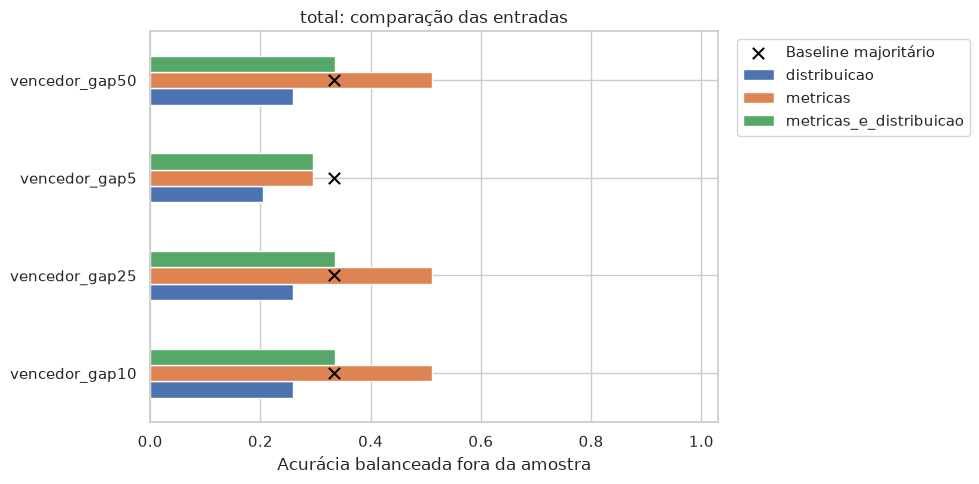

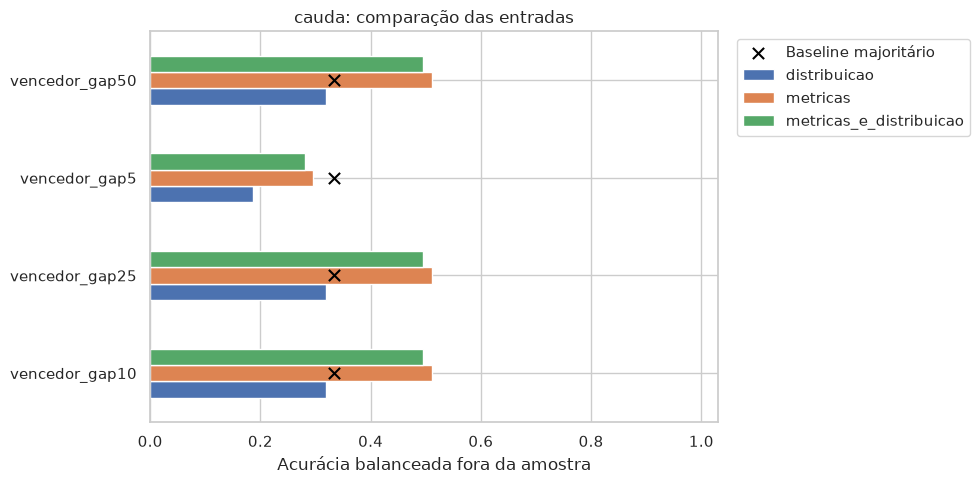

In [15]:
if not model_scores.empty:
    incremental = []
    for (scope, target, kind), group in model_scores.groupby(["escopo", "resposta", "tipo"]):
        values = group.set_index("entradas")["score_modelo"]
        if {"metricas", "metricas_e_distribuicao"} <= set(values.index):
            gain = (values["metricas_e_distribuicao"] - values["metricas"]
                    if kind == "classificacao" else
                    values["metricas"] - values["metricas_e_distribuicao"])
            incremental.append({
                "escopo": scope, "resposta": target, "tipo": kind,
                "score_metricas": values["metricas"],
                "score_com_distribuicao": values["metricas_e_distribuicao"],
                "ganho_ao_incluir_distribuicao": gain,
            })
    save_table(incremental, "valor_incremental_distribuicao")

    scope_comparison = model_scores.pivot(
        index=["resposta", "tipo", "entradas", "metrica"],
        columns="escopo", values="score_modelo",
    ).reset_index()
    if {"total", "cauda"} <= set(scope_comparison):
        scope_comparison["ganho_cauda_sobre_total"] = np.where(
            scope_comparison["tipo"].eq("classificacao"),
            scope_comparison["cauda"] - scope_comparison["total"],
            scope_comparison["total"] - scope_comparison["cauda"],
        )
    save_table(scope_comparison, "modelos_total_versus_cauda")

    for scope in SCOPES:
        summary = model_scores[
            model_scores["escopo"].eq(scope) & model_scores["tipo"].eq("classificacao")
        ]
        if summary.empty:
            continue
        pivot = summary.pivot(index="resposta", columns="entradas", values="score_modelo")
        ax = pivot.plot.barh(figsize=(10, 5))
        dummy = summary.groupby("resposta")["score_baseline"].first().reindex(pivot.index)
        ax.scatter(dummy, np.arange(len(pivot)), marker="x", color="black", s=65,
                   label="Baseline majoritário")
        ax.set(xlim=(0, 1.03), xlabel="Acurácia balanceada fora da amostra", ylabel="",
               title=f"{scope}: comparação das entradas")
        ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
        finish_figure(ax.figure, f"modelos_classificacao_{scope}")

if not importance_folds.empty:
    importance_records = []
    keys = ["escopo", "resposta", "entradas", "caracteristica", "unidade"]
    for key, group in importance_folds.groupby(keys):
        mean = np.average(group["importancia"], weights=group["n_teste"])
        spread = np.sqrt(np.average((group["importancia"] - mean) ** 2, weights=group["n_teste"]))
        importance_records.append(dict(zip(keys, key)) | {
            "importancia_media_ponderada": mean, "dispersao_entre_folds": spread,
            "n_folds": len(group),
        })
    importance_summary = save_table(importance_records, "importancias_permutacao_resumo", show=False)
    for scope in SCOPES:
        selected = importance_summary[
            importance_summary["escopo"].eq(scope)
            & importance_summary["resposta"].eq(ILLUSTRATION_CLASS_TARGET)
            & importance_summary["entradas"].eq("metricas_e_distribuicao")
        ].sort_values("importancia_media_ponderada")
        if selected.empty:
            continue
        fig, ax = plt.subplots(figsize=(9, max(4, len(selected) * .35)))
        ax.barh(selected["caracteristica"], selected["importancia_media_ponderada"])
        ax.axvline(0, color="black", linewidth=.8)
        ax.set(xlabel="Queda média ponderada de macro F1 no teste",
               title=f"{scope}: importância por permutação ({ILLUSTRATION_CLASS_TARGET})")
        finish_figure(fig, f"importancias_{scope}_{ILLUSTRATION_CLASS_TARGET}")


As diferenças entre entradas e entre escopos são descritivas nas mesmas divisões de
validação. Ganho positivo significa melhora na métrica correspondente; não é um p-valor.
Se ambos os escores forem fracos, não se interpreta importância como evidência de que
uma característica permita selecionar bem o algoritmo.

As próximas matrizes e dispersões usam exclusivamente predições fora da amostra.
As árvores desenhadas depois são reajustadas em todos os dados apenas para visualizar
regras; seus nós e cortes não são uma avaliação independente de desempenho.
Nos classificadores, value reflete os pesos de classe, enquanto samples é a contagem de instâncias.


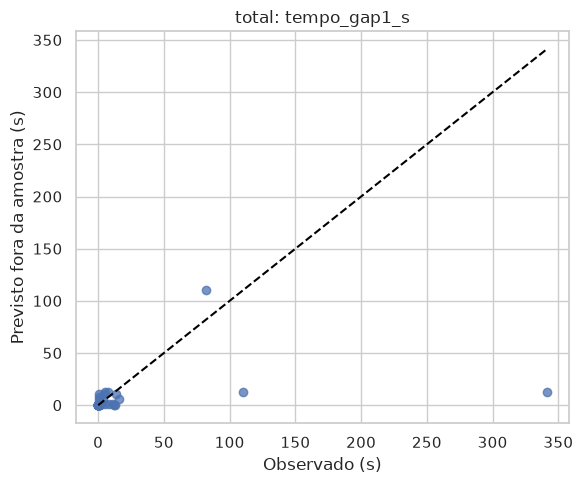

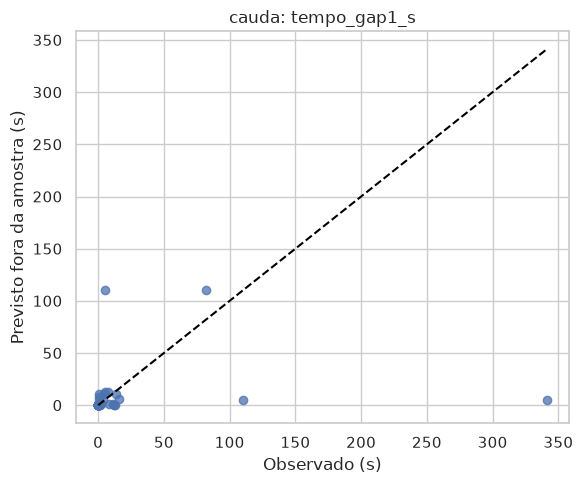

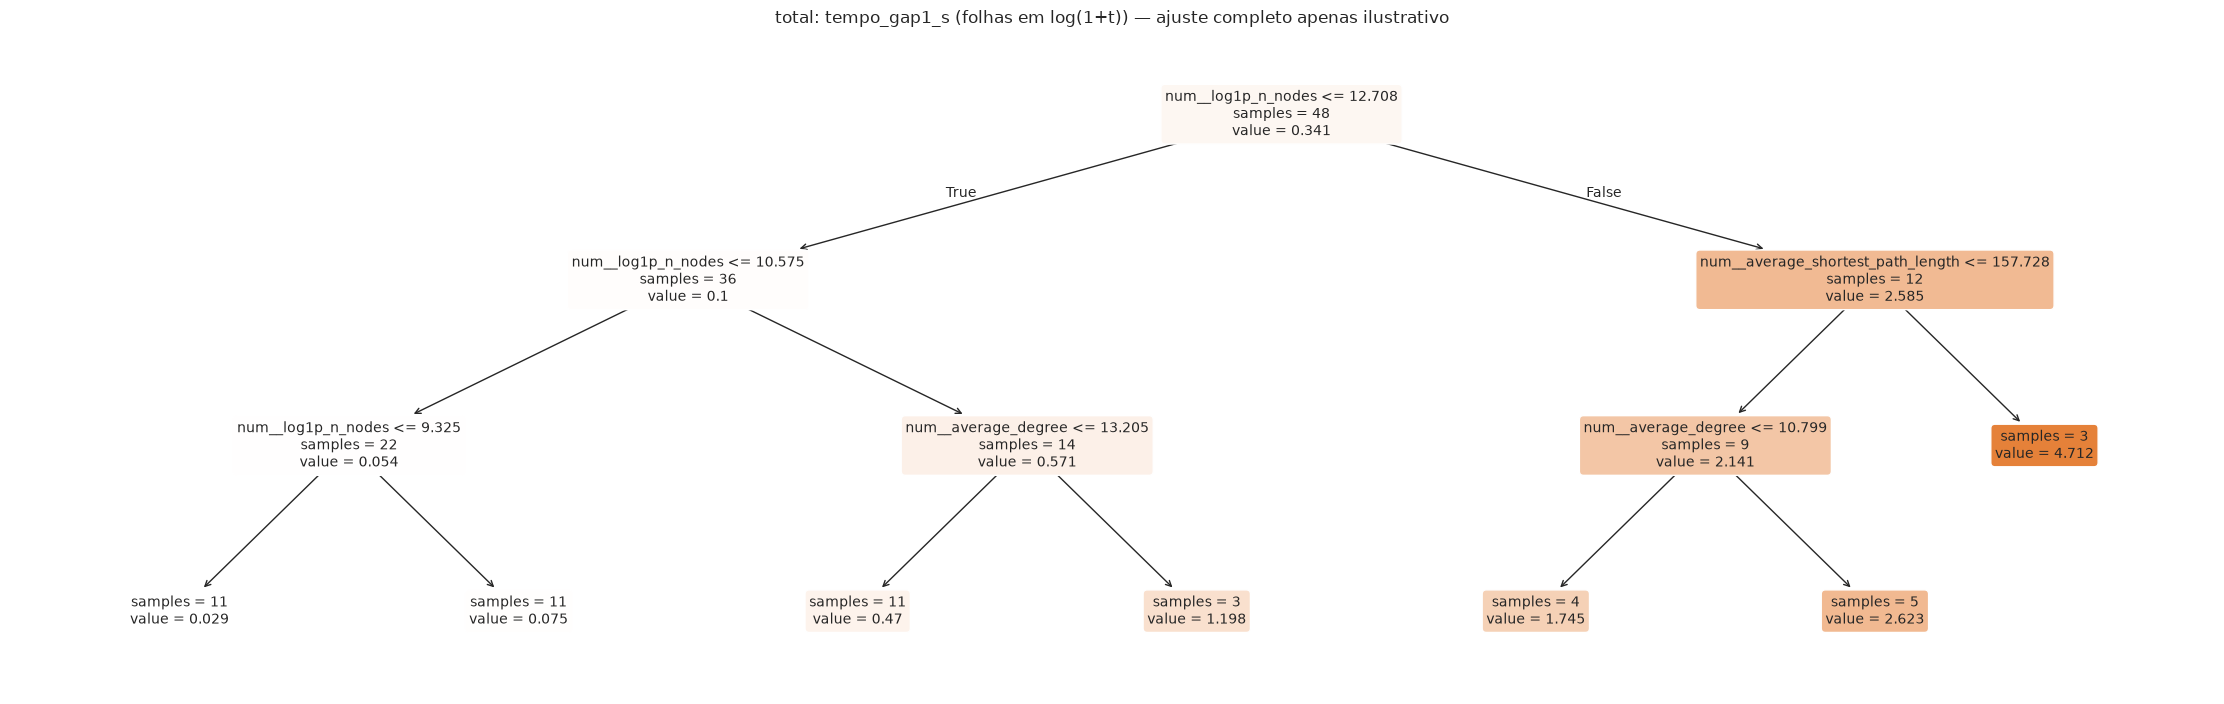

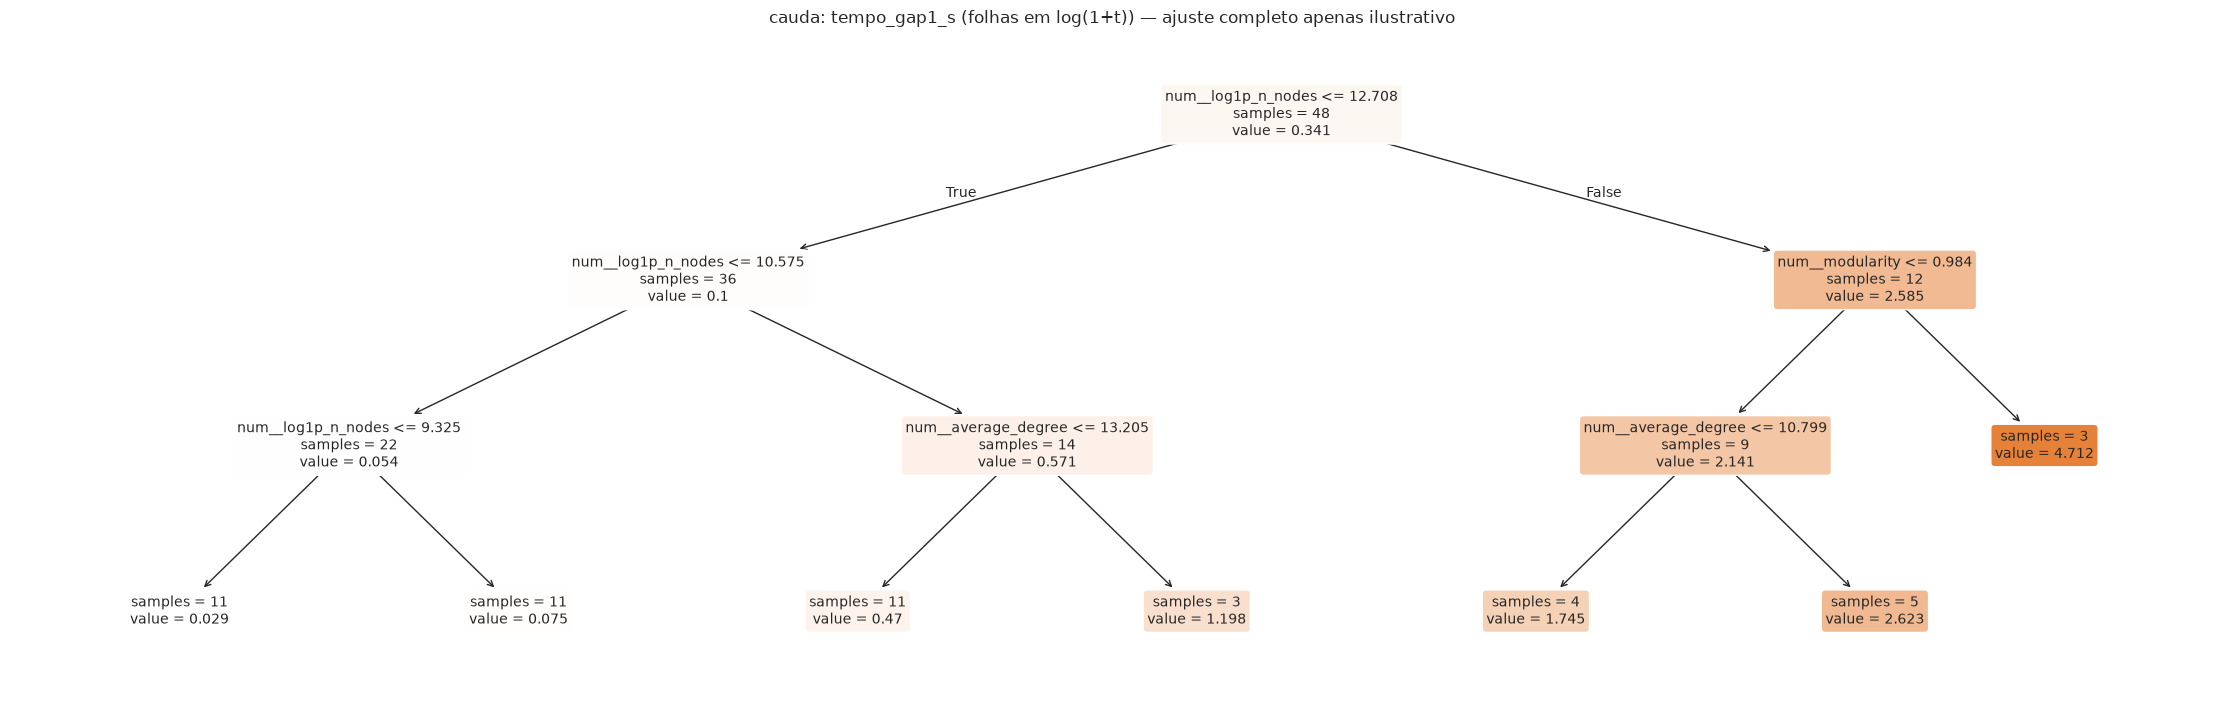

In [16]:
if not oof_predictions.empty:
    for scope in SCOPES:
        common = oof_predictions[
            oof_predictions["escopo"].eq(scope)
            & oof_predictions["entradas"].eq("metricas_e_distribuicao")
        ]
        classification = common[common["resposta"].eq(ILLUSTRATION_CLASS_TARGET)]
        if not classification.empty:
            truth = classification["verdadeiro"].astype(str)
            prediction = classification["previsto"].astype(str)
            labels = sorted(set(truth) | set(prediction))
            fig, ax = plt.subplots(figsize=(7, 5))
            ConfusionMatrixDisplay(
                confusion_matrix(truth, prediction, labels=labels),
                display_labels=labels,
            ).plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=25)
            ax.set_title(f"{scope}: confusão fora da amostra — {ILLUSTRATION_CLASS_TARGET}")
            finish_figure(fig, f"confusao_{scope}_{ILLUSTRATION_CLASS_TARGET}")

        regression = common[common["resposta"].eq(ILLUSTRATION_REG_TARGET)]
        if not regression.empty:
            truth = pd.to_numeric(regression["verdadeiro"]).to_numpy()
            prediction = pd.to_numeric(regression["previsto"]).to_numpy()
            fig, ax = plt.subplots(figsize=(6, 5))
            ax.scatter(truth, prediction, alpha=.75)
            lo, hi = min(truth.min(), prediction.min()), max(truth.max(), prediction.max())
            ax.plot([lo, hi], [lo, hi], linestyle="--", color="black")
            ax.set(xlabel="Observado (s)", ylabel="Previsto fora da amostra (s)",
                   title=f"{scope}: {ILLUSTRATION_REG_TARGET}")
            finish_figure(fig, f"regressao_{scope}_{ILLUSTRATION_REG_TARGET}")

for (scope, target, kind), pipeline in FITTED_EXAMPLES.items():
    estimator = pipeline.named_steps["estimator"]
    if isinstance(estimator, TransformedTargetRegressor):
        estimator = estimator.regressor_
    names = pipeline.named_steps["preprocess"].get_feature_names_out()
    fig, ax = plt.subplots(figsize=(max(10, min(24, estimator.get_n_leaves() * 3.2)),
                                    max(4.5, estimator.get_depth() * 2.4)))
    kwargs = {"class_names": list(estimator.classes_)} if kind == "classificacao" else {}
    plot_tree(estimator, feature_names=list(names), filled=True, rounded=True,
              impurity=False, proportion=False, precision=3, fontsize=10, ax=ax, **kwargs)
    unit = " (folhas em log(1+t))" if target.startswith("tempo_") else ""
    ax.set_title(f"{scope}: {target}{unit} — ajuste completo apenas ilustrativo")
    finish_figure(fig, f"arvore_ilustrativa_{scope}_{target}")
    rules = export_text(estimator, feature_names=list(names), decimals=5)
    (TABLE_DIR / f"regras_ilustrativas_{scope}_{target}.txt").write_text(rules, encoding="utf-8")


## 11. Figuras de regimes topológicos

Cada ponto representa uma instância. O tamanho amostral é o número de grafos,
não o número de vértices. As cores indicam o vencedor exclusivo em gap1.
Esses mapas são exploratórios; regiões aparentes podem refletir a família de origem.


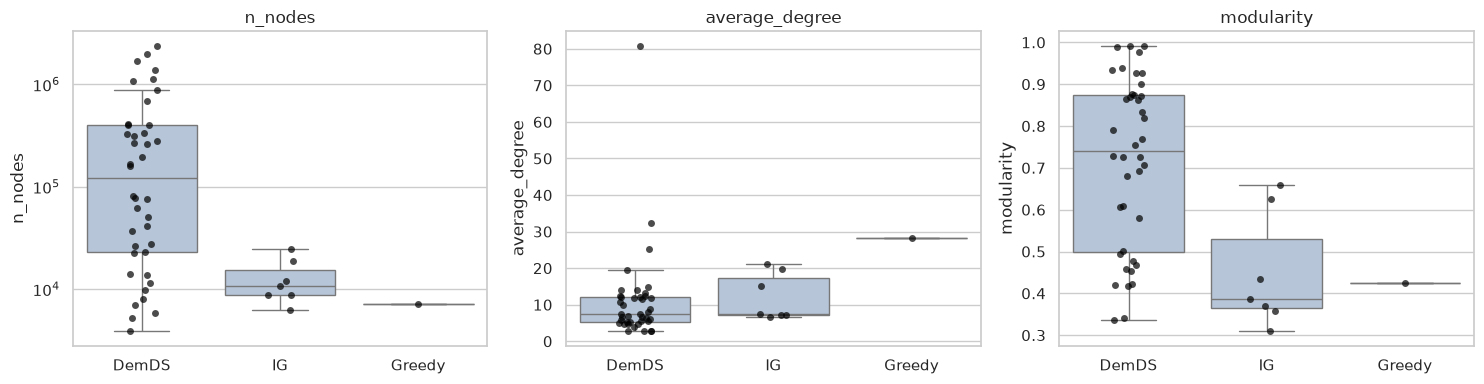

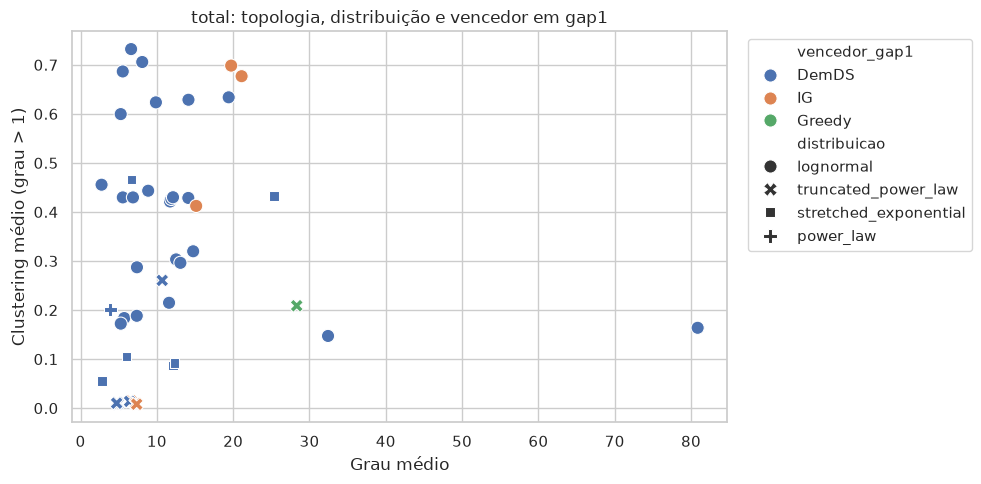

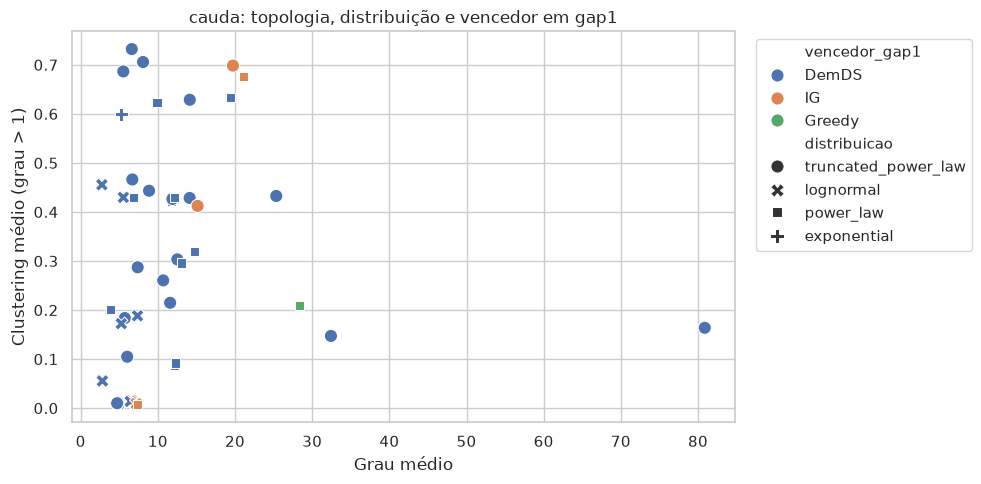

In [17]:
winner_column = "vencedor_gap1"
map_subset = base.loc[base["status_vencedor_gap1"].eq("unico")].copy()
map_features = [c for c in ["n_nodes", "average_degree", "modularity"]
                if c in NUMERIC_FEATURES and map_subset[c].notna().any()]
if not map_subset.empty and map_features:
    fig, axes = plt.subplots(1, len(map_features), figsize=(5 * len(map_features), 4), squeeze=False)
    for ax, feature in zip(axes.ravel(), map_features):
        sns.boxplot(data=map_subset, x=winner_column, y=feature, showfliers=False,
                    color="lightsteelblue", ax=ax)
        sns.stripplot(data=map_subset, x=winner_column, y=feature, color="black",
                      jitter=.12, alpha=.7, ax=ax)
        ax.set(xlabel="", title=feature)
        if feature == "n_nodes":
            ax.set_yscale("log")
    finish_figure(fig, "topologia_por_vencedor_gap1")

for scope, frame in bases.items():
    subset = frame.loc[frame["status_vencedor_gap1"].eq("unico")].copy()
    needed = ["average_degree", "mean_clustering_degree_gt_1", "vencedor_gap1", "distribuicao"]
    subset = subset.dropna(subset=needed)
    if subset.empty:
        continue
    fig, ax = plt.subplots(figsize=(10, 5))
    sns.scatterplot(data=subset, x="average_degree", y="mean_clustering_degree_gt_1",
                    hue="vencedor_gap1", style="distribuicao", s=90, ax=ax)
    ax.set(xlabel="Grau médio", ylabel="Clustering médio (grau > 1)",
           title=f"{scope}: topologia, distribuição e vencedor em gap1")
    ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
    finish_figure(fig, f"regimes_topologicos_{scope}")


## 12. Exportação, reprodutibilidade e roteiro de interpretação

Todas as tabelas completas e figuras ficam em RESULTS_DIR/final_stats/run_... .
Cada execução cria uma pasta nova. Os arquivos de entrada não são alterados.
A tabela de auditoria reúne coerções, dados ausentes e observações de consistência.
O manifesto guarda configuração, versões e SHA-256 dos arquivos de entrada.

A tabela testes_todas_familias acrescenta um Holm sobre todos os testes executados.
Ela é mais conservadora e serve quando as conclusões usam qualquer uma das famílias.
Correções não compensam seleção de hipóteses, dependência entre redes ou comparação
de instâncias com pré-processamentos diferentes.

Para interpretar os resultados:
1. Verifique cobertura, orçamento e relógio dos tempos; os ótimos são os valores da coluna dms.
2. Relate n, proporção de ausências/insucessos, mediana, dispersão e tamanho de efeito.
3. Examine correlações entre características antes de atribuir uma relação à topologia.
4. Para o vencedor categórico, use associação, comparações entre grupos e classificação.
5. Compare a árvore ao baseline fora da amostra e veja se a distribuição acrescenta informação.
6. Compare total e cauda como análises da mesma coleção e descreva limitações de amostra.

**O que exige dados adicionais:** Friedman e Wilcoxon entre algoritmos, diagramas de
diferença crítica, performance profiles, regret de seleção e comparação final de gaps
de cada algoritmo exigem medidas por algoritmo e instância, além das seeds quando
disponíveis. O gráfico opcional de diferenças médias é apenas descritivo.
Para tempos até alvo não atingido, preserve tempo de censura e indicador de atingimento.
Seeds são repetições da mesma instância e não devem multiplicar artificialmente o
número de grafos em uma análise de correlação topológica. Se for resumir seeds por
instância para um teste pareado, defina antes a agregação e a política de insucessos.


In [18]:
all_test_rows = []
for family, frame in [
    ("spearman", correlations),
    ("associacao_categorica", categorical_associations),
    ("kruskal", numeric_groups),
    ("pares_cliff", posthoc),
]:
    if not frame.empty:
        selected = frame.loc[frame["p_perm"].notna()].copy()
        selected.insert(0, "familia", family)
        all_test_rows.append(selected.drop(columns=["p_holm", "significativo_holm"], errors="ignore"))
all_tests = (pd.concat(all_test_rows, ignore_index=True, sort=False)
             if all_test_rows else pd.DataFrame(columns=["p_perm"]))
all_tests = adjust_holm(all_tests, adjusted_col="p_holm_todas_familias")
save_table(all_tests, "testes_todas_familias", show=False)
resolution_rows = []
for family_name, test_frame in [
    ("spearman", correlations), ("associacao_categorica", categorical_associations),
    ("kruskal", numeric_groups), ("pares_cliff", posthoc), ("todas_familias", all_tests),
]:
    n_tests = int(test_frame["p_perm"].notna().sum()) if "p_perm" in test_frame else 0
    minimum_adjusted = min(1.0, n_tests / (N_PERM + 1))
    resolution_rows.append({
        "familia": family_name, "n_testes": n_tests, "menor_p_monte_carlo": 1 / (N_PERM + 1),
        "menor_p_holm_na_primeira_rejeicao": minimum_adjusted,
        "n_perm_recomendado_minimo": max(0, int(np.ceil(n_tests / ALPHA))),
    })
    if n_tests and minimum_adjusted >= ALPHA:
        note("resolução dos testes", f"{family_name}: aumente N_PERM para mais de "
             f"{n_tests / ALPHA:.0f} se precisar resolver a primeira rejeição com Holm.")
save_table(resolution_rows, "resolucao_testes_monte_carlo")
save_table(AUDIT, "auditoria_geral")

FILES = [
    "general_metrics.csv", "mds_gaps_final.csv", "mds_solucoes_final.csv",
    "melhores_tempos_full.csv", "distribuicoes_escolhidas.csv", "otimos.csv",
]
versions = {name: module.__version__ for name, module in [
    ("numpy", np), ("pandas", pd), ("scipy", scipy),
    ("matplotlib", matplotlib), ("seaborn", sns), ("scikit-learn", sklearn),
]}
manifest = {
    "run_id": RUN_ID, "python": platform.python_version(), "versions": versions,
    "results_dir": str(RESULTS_DIR), "output_dir": str(OUTPUT_DIR),
    "configuration": {
        "seed": SEED, "alpha": ALPHA, "n_permutations": N_PERM, "n_bootstrap": N_BOOT,
        "optimal_values_column": "dms", "join_key": "instancia",
        "cv_unit": "instancia",
        "min_n_assoc": MIN_N_ASSOC, "min_n_group": MIN_N_GROUP, "min_n_model": MIN_N_MODEL,
        "cv_folds": CV_FOLDS, "tree_max_depth": TREE_MAX_DEPTH,
        "tree_min_samples_leaf": TREE_MIN_SAMPLES_LEAF,
        "include_ties_in_models": INCLUDE_TIES_IN_MODELS,
        "allow_mixed_budgets_models": ALLOW_MIXED_BUDGETS_MODELS,
        "run_posthoc": RUN_POSTHOC, "importance_repeats": IMPORTANCE_REPEATS,
        "numeric_features": NUMERIC_FEATURES, "model_features": MODEL_FEATURES,
        "class_targets": CLASS_TARGETS, "numeric_targets": NUMERIC_TARGETS,
    },
    "inputs": {},
}
for filename in FILES:
    path = RESULTS_DIR / filename
    if path.is_file():
        manifest["inputs"][filename] = {
            "bytes": path.stat().st_size,
            "sha256": hashlib.sha256(path.read_bytes()).hexdigest(),
        }
(OUTPUT_DIR / "manifesto.json").write_text(
    json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8"
)
guide = (
    "Resultados de final_stats.ipynb\n\n"
    "base_total.csv e base_cauda.csv: junções sem multiplicar instâncias.\n"
    "correlacoes_spearman.csv: rho, p por permutação, Holm, IC e correlação parcial descritiva.\n"
    "associacoes_distribuicao_vencedor.csv: V de Cramér e p por permutação.\n"
    "comparacoes_grupos_kruskal.csv e comparacoes_pares_cliff.csv: testes e efeitos.\n"
    "modelos_validacao_fora_amostra.csv: escores OOF e baseline.\n"
    "predicoes_fora_amostra.csv: uma previsão de teste por instância, tarefa e entrada.\n"
    "modelos_omitidos_motivos.csv e auditoria_geral.csv: limitações e registros de qualidade.\n"
    "testes_todas_familias.csv: Holm adicional sobre o conjunto de testes.\n"
    "Figuras de árvores e regras são ilustrativas; avaliação está nos escores OOF.\n"
    "Tempos e gaps refletem exclusivamente os resumos fornecidos nos CSVs.\n"
)
(OUTPUT_DIR / "LEIA_ME.txt").write_text(guide, encoding="utf-8")
print(f"Concluído: {len(TABLES)} tabelas.")
print(f"Tabelas: {TABLE_DIR}")
print(f"Figuras: {FIG_DIR}")
print("Confira auditoria_geral.csv e modelos_omitidos_motivos.csv antes de interpretar os resultados.")


,familia,n_testes,menor_p_monte_carlo,menor_p_holm_na_primeira_rejeicao,n_perm_recomendado_minimo
0,spearman,91,5e-05,0.00455,1820
1,associacao_categorica,12,5e-05,0.0006,240
2,kruskal,26,5e-05,0.0013,520
3,pares_cliff,146,5e-05,0.0073,2920
4,todas_familias,275,5e-05,0.01375,5500


,tema,mensagem,n
0,general_metrics.csv,Arquivo lido.,50
1,mds_gaps_final.csv,Arquivo lido.,50
2,mds_solucoes_final.csv,Arquivo lido.,50
3,melhores_tempos_full.csv,Arquivo lido.,50
4,distribuicoes_escolhidas.csv,Arquivo lido.,100
5,otimos.csv,Arquivo lido.,50
6,orçamento,Há limites_s distintos. Separe os orçamentos a...,NaN


Concluído: 41 tabelas.
Tabelas: /home/fernando/complex-networks/results/final_stats/run_20261120_032308_235404_UTC/tabelas
Figuras: /home/fernando/complex-networks/results/final_stats/run_20261120_032308_235404_UTC/figuras
Confira auditoria_geral.csv e modelos_omitidos_motivos.csv antes de interpretar os resultados.


## Referências dos métodos e da implementação

Consultadas para a construção deste notebook em 19/11/2026:

- [SciPy: Spearman e limitação do p assintótico em amostras pequenas](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.spearmanr.html).
- [SciPy: testes de permutação e intercambialidade](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.permutation_test.html).
- [SciPy: associação entre variáveis nominais](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.contingency.association.html).
- [SciPy: Kruskal–Wallis e necessidade de comparações posteriores](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.kruskal.html).
- [rstatix: definição de eta quadrado baseado em H](https://rpkgs.datanovia.com/rstatix/reference/kruskal_effsize.html).
- [SciPy: Friedman para medidas repetidas](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.friedmanchisquare.html).
- [scikit-learn: validação cruzada](https://scikit-learn.org/stable/modules/cross_validation.html).
- [scikit-learn: validação aninhada quando se ajustam hiperparâmetros](https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html).
- [scikit-learn: importância por permutação e características correlacionadas](https://scikit-learn.org/stable/modules/permutation_importance.html).
- [Holm (1979): artigo original sobre correção de múltiplos testes](https://www.jstor.org/stable/4615733).

O notebook utiliza as funções documentadas quando aplicáveis e implementações explícitas
de permutação e Holm, evitando depender de aproximações assintóticas para amostras pequenas.
